This notebook documents the historical final calculation. Its legacy likelihood is retained for provenance; use `scripts/run_final_limits.py` for the tested and corrected result described in `audit/REPORT.md`.


What is needed:

-   `GRMHD/grmhdDataAfterImageS.npy`
-   `GRMHD/EVPA.npy`
-   `NormR.csv`


# libraries, functions, ...


In [4]:
import numpy as np
from copy import deepcopy
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from utils.libanaly import Plot_Background, plot_quivers, CircleCalc, ImageS
from scipy.linalg import cho_factor, cho_solve

# Part GRMHD: calucate std or cor (without Axion)


What we get:

-   `cor_grmhd` it is a number (rad) representing the standard deviation of different time GRMHD simulations


In [5]:
grmhdDataAfterImageS = np.load(
    "./GRMHD/data_out/grmhdDataAfterImageS_alpha=0.3_res=400.npy"
)
EVPA = np.load("./GRMHD/data_out/EVPA_alpha=0.3_res=400.npy")  # rad
# EVPA_without_axion = EVPA[:, 0, :, :]

In [6]:
# P_without_axion = np.sqrt(
#     grmhdDataAfterImageS[:, 0, :, :, 1] ** 2 + grmhdDataAfterImageS[:, 0, :, :, 2] ** 2
# )

In [7]:
grmhdDataAfterImageS = {}
EVPA = {}
EVPA_1d = {}
EVPA_1d_10deg = {}

for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    grmhdDataAfterImageS[alpha] = np.load(
        f"GRMHD/data_out/grmhdDataAfterImageS_alpha={alpha}_res=100.npy"
    )
    EVPA[alpha] = np.load(f"GRMHD/data_out/EVPA_alpha={alpha}_res=100.npy")
    EVPA_1d[alpha] = np.load(f"GRMHD/data_out/EVPA_1d_alpha={alpha}_res=100.npy")
    EVPA_1d_10deg[alpha] = np.load(
        f"GRMHD/data_out/EVPA_1d_10deg_alpha={alpha}_res=100.npy"
    )

grmhdDataAfterImageS_400 = {}
EVPA_400 = {}
EVPA_400_1d = {}
EVPA_400_1d_10deg = {}

for alpha in [0.3]:
    grmhdDataAfterImageS_400[alpha] = np.load(
        f"GRMHD/data_out/grmhdDataAfterImageS_alpha={alpha}_res=400.npy"
    )
    EVPA_400[alpha] = np.load(f"GRMHD/data_out/EVPA_alpha={alpha}_res=400.npy")
    EVPA_400_1d[alpha] = np.load(f"GRMHD/data_out/EVPA_1d_alpha={alpha}_res=400.npy")
    EVPA_400_1d_10deg[alpha] = np.load(
        f"GRMHD/data_out/EVPA_1d_10deg_alpha={alpha}_res=400.npy"
    )

In [8]:
condition = np.load("./EHT-Imaging/data_out/condition.npy", allow_pickle=True)

In [9]:
rg_per_pixel = 0.51073125
# condition2to9 = np.array(
#     [
#         [
#             2 <= np.sqrt((i - 31.5) ** 2 + (j - 31.5) ** 2) * rg_per_pixel <= 9
#             for j in range(64)
#         ]
#         for i in range(64)
#     ]
# )


# 注意由于这里求的都是不含轴子效应的结果，所以理应与alpha无关
def get_EVPA_diff_xday(diff, alpha=0.3):
    start = 1600
    end = 3000
    grmhd_step = 10
    step = 30  # 30 * 0.1 *8h=1day
    r_step = step // grmhd_step

    diff_x_r_step = int(diff * r_step)
    evpa_diff_temp = np.zeros(((end - start) // grmhd_step - diff_x_r_step + 1, 64, 64))
    evpa_diff_temp_with_condition = np.zeros(
        ((end - start) // grmhd_step - diff_x_r_step + 1, 64, 64)
    )
    EVPA_without_axion = EVPA_400[alpha][:, 0, :, :]
    P_without_axion = np.sqrt(
        grmhdDataAfterImageS_400[alpha][:, 0, :, :, 1] ** 2
        + grmhdDataAfterImageS_400[alpha][:, 0, :, :, 2] ** 2
    )
    for num in range((end - start) // grmhd_step - diff_x_r_step + 1):
        evpa_diff_temp[num] = CircleCalc.circle_sub_evpa(
            EVPA_without_axion[num + diff_x_r_step], EVPA_without_axion[num]
        )
        # condition = (
        #     P_without_axion[num + diff_x_r_step] > P_without_axion[num].max() * 0.1
        # ) * (
        #     P_without_axion[num] > P_without_axion[num].max() * 0.1
        # )  # can be optimized
        evpa_diff_temp_with_condition[num] = evpa_diff_temp[num] * condition
        evpa_diff_temp_with_condition[num][
            evpa_diff_temp_with_condition[num] == 0
        ] = np.nan
    return evpa_diff_temp, evpa_diff_temp_with_condition


def get_EVPA_diff_1day(**kwargs):
    return get_EVPA_diff_xday(1, **kwargs)


def get_EVPA_diff_8h(**kwargs):
    return get_EVPA_diff_xday(1 / 3, **kwargs)

In [10]:
evpa_diff, evpa_diff_with_condition = get_EVPA_diff_1day()

In [11]:
evpa_diff_with_condition.shape

(138, 64, 64)

In [ ]:
from matplotlib.ticker import FormatStrFormatter


def gaussian(x, amplitude, mean, stddev):
    return (
        amplitude
        / np.sqrt(2 * np.pi)
        / stddev
        * np.exp(-(((x - mean) / stddev) ** 2) / 2)
    )


# def _gaussian_noAmp(x, mean, sigma):
#     return gaussian(x, 1, mean, sigma)


def plot_gaussian1(
    data_temp,
    bins=100,
    plot_range=(-7, 7),
    plot=True,
    initial_guess=[1, 0, 1],
    rm_nan=True,
    figsize=(16, 16),
):
    plt.rcParams["text.usetex"] = True
    plt.rcParams["font.family"] = "Times New Roman"
    plt.rcParams[
        "text.latex.preamble"
    ] = r"""
    \usepackage{amsmath}
    \usepackage{amssymb}
    """
    plt.rcParams["mathtext.fontset"] = "custom"
    plt.rcParams["mathtext.rm"] = "Times New Roman"  # 设置正常文本的字体
    plt.rcParams["mathtext.it"] = "Times New Roman:italic"  # 设置斜体文本的字体
    plt.rcParams["mathtext.bf"] = "Times New Roman:bold"  # 设置粗体文本的字体
    # 生成随机数据
    np.random.seed(42)
    data = deepcopy(data_temp)
    if rm_nan == True:
        data = data[np.isfinite(data)]

    # 生成直方图
    hist, bin_edges = np.histogram(data, bins=bins, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # 初始猜测值
    # initial_guess = initial_guess

    # 使用curve_fit进行拟合
    params, covariance = curve_fit(
        gaussian, bin_centers, hist, p0=initial_guess, maxfev=5000000
    )

    if plot == True:
        # 绘制直方图
        fig = plt.figure(figsize=figsize, dpi=300)
        plt.hist(data, bins=bins, density=True, range=plot_range)

        # 绘制拟合曲线
        x_range = np.linspace(*plot_range, 100)
        fit_curve = gaussian(x_range, *params)
        # "$y="+f"{params[0]:.3f}"+r"\exp{\frac{x-"+f"{params[1]:.3f}"+r"^2}{2\cdot "+f"{params[2]:.3f}"+"^2}}$"
        plt.plot(
            x_range,
            fit_curve,
            "r-",
            label=r"$P=\frac{A}{\sqrt{2\pi}\sigma} e^{-\frac{(x-x_0)^2}{2\sigma^2}}$ , "
            + f"$A={params[0]:.2f},\ x_0={params[1]:.2f}^\circ,\ \sigma={params[2]:.2f}^\circ$",
            color="brown",
        )
        plt.xticks(fontsize=24)
        plt.yticks(fontsize=24)

        # Add degree symbol to x-axis ticks
        plt.gca().xaxis.set_major_formatter(FormatStrFormatter(r"$%g^\circ$"))

        # plt.xlabel(r"$\frac{\Delta I_{\left("+f"{day}"+r"\mathrm{day}\right)}}{I}$",fontsize=30)
        plt.xlabel(r"$\Delta \mathrm{EVPA}$", fontsize=24)
        plt.gca().spines["top"].set_visible(False)
        plt.gca().spines["right"].set_visible(False)
        plt.legend(fontsize=24)

        plt.show()

    return params, covariance

<>:70: SyntaxWarning: invalid escape sequence '\ '
<>:70: SyntaxWarning: invalid escape sequence '\c'
<>:70: SyntaxWarning: invalid escape sequence '\c'
<>:70: SyntaxWarning: invalid escape sequence '\ '
<>:70: SyntaxWarning: invalid escape sequence '\c'
<>:70: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_592537/3739397850.py:70: SyntaxWarning: invalid escape sequence '\ '
  + f"$A={params[0]:.2f},\ x_0={params[1]:.2f}^\circ,\ \sigma={params[2]:.2f}^\circ$",
/tmp/ipykernel_592537/3739397850.py:70: SyntaxWarning: invalid escape sequence '\c'
  + f"$A={params[0]:.2f},\ x_0={params[1]:.2f}^\circ,\ \sigma={params[2]:.2f}^\circ$",
/tmp/ipykernel_592537/3739397850.py:70: SyntaxWarning: invalid escape sequence '\c'
  + f"$A={params[0]:.2f},\ x_0={params[1]:.2f}^\circ,\ \sigma={params[2]:.2f}^\circ$",


In [13]:
# plt.imshow(evpa_diff_with_condition[10], cmap="jet")
# plt.colorbar()

In [14]:
# plt.imshow(evpa_diff_with_condition[0], cmap="jet")
# plt.colorbar()

In [15]:
from utils.libanaly import plot_gaussian, fit_gaussian2

In [16]:
evpa_diff_with_condition.reshape(-1, 1)[:, 0].max()

np.float64(nan)

In [17]:
_, _cor_grmhd_tmp_ = fit_gaussian2(
    evpa_diff_with_condition.reshape(-1, 1)[:, 0] / np.pi * 180,
    rm_nan=True,
    bins=100,
    threshold=0.2,
)

/home/canoziia/MyProject/PHYS/EHT_ZC/utils/libanaly.py:107: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


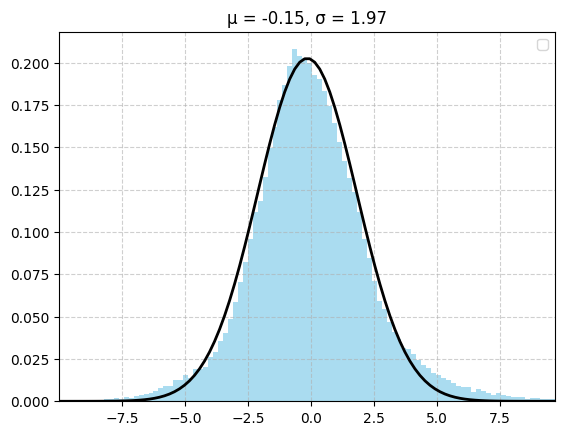

In [18]:
plot_gaussian(
    evpa_diff_with_condition.reshape(-1, 1)[:, 0] / np.pi * 180,
    bins=100,
    mean=-0.147,
    sigma=1.97,
)

/tmp/ipykernel_592537/3739397850.py:65: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(


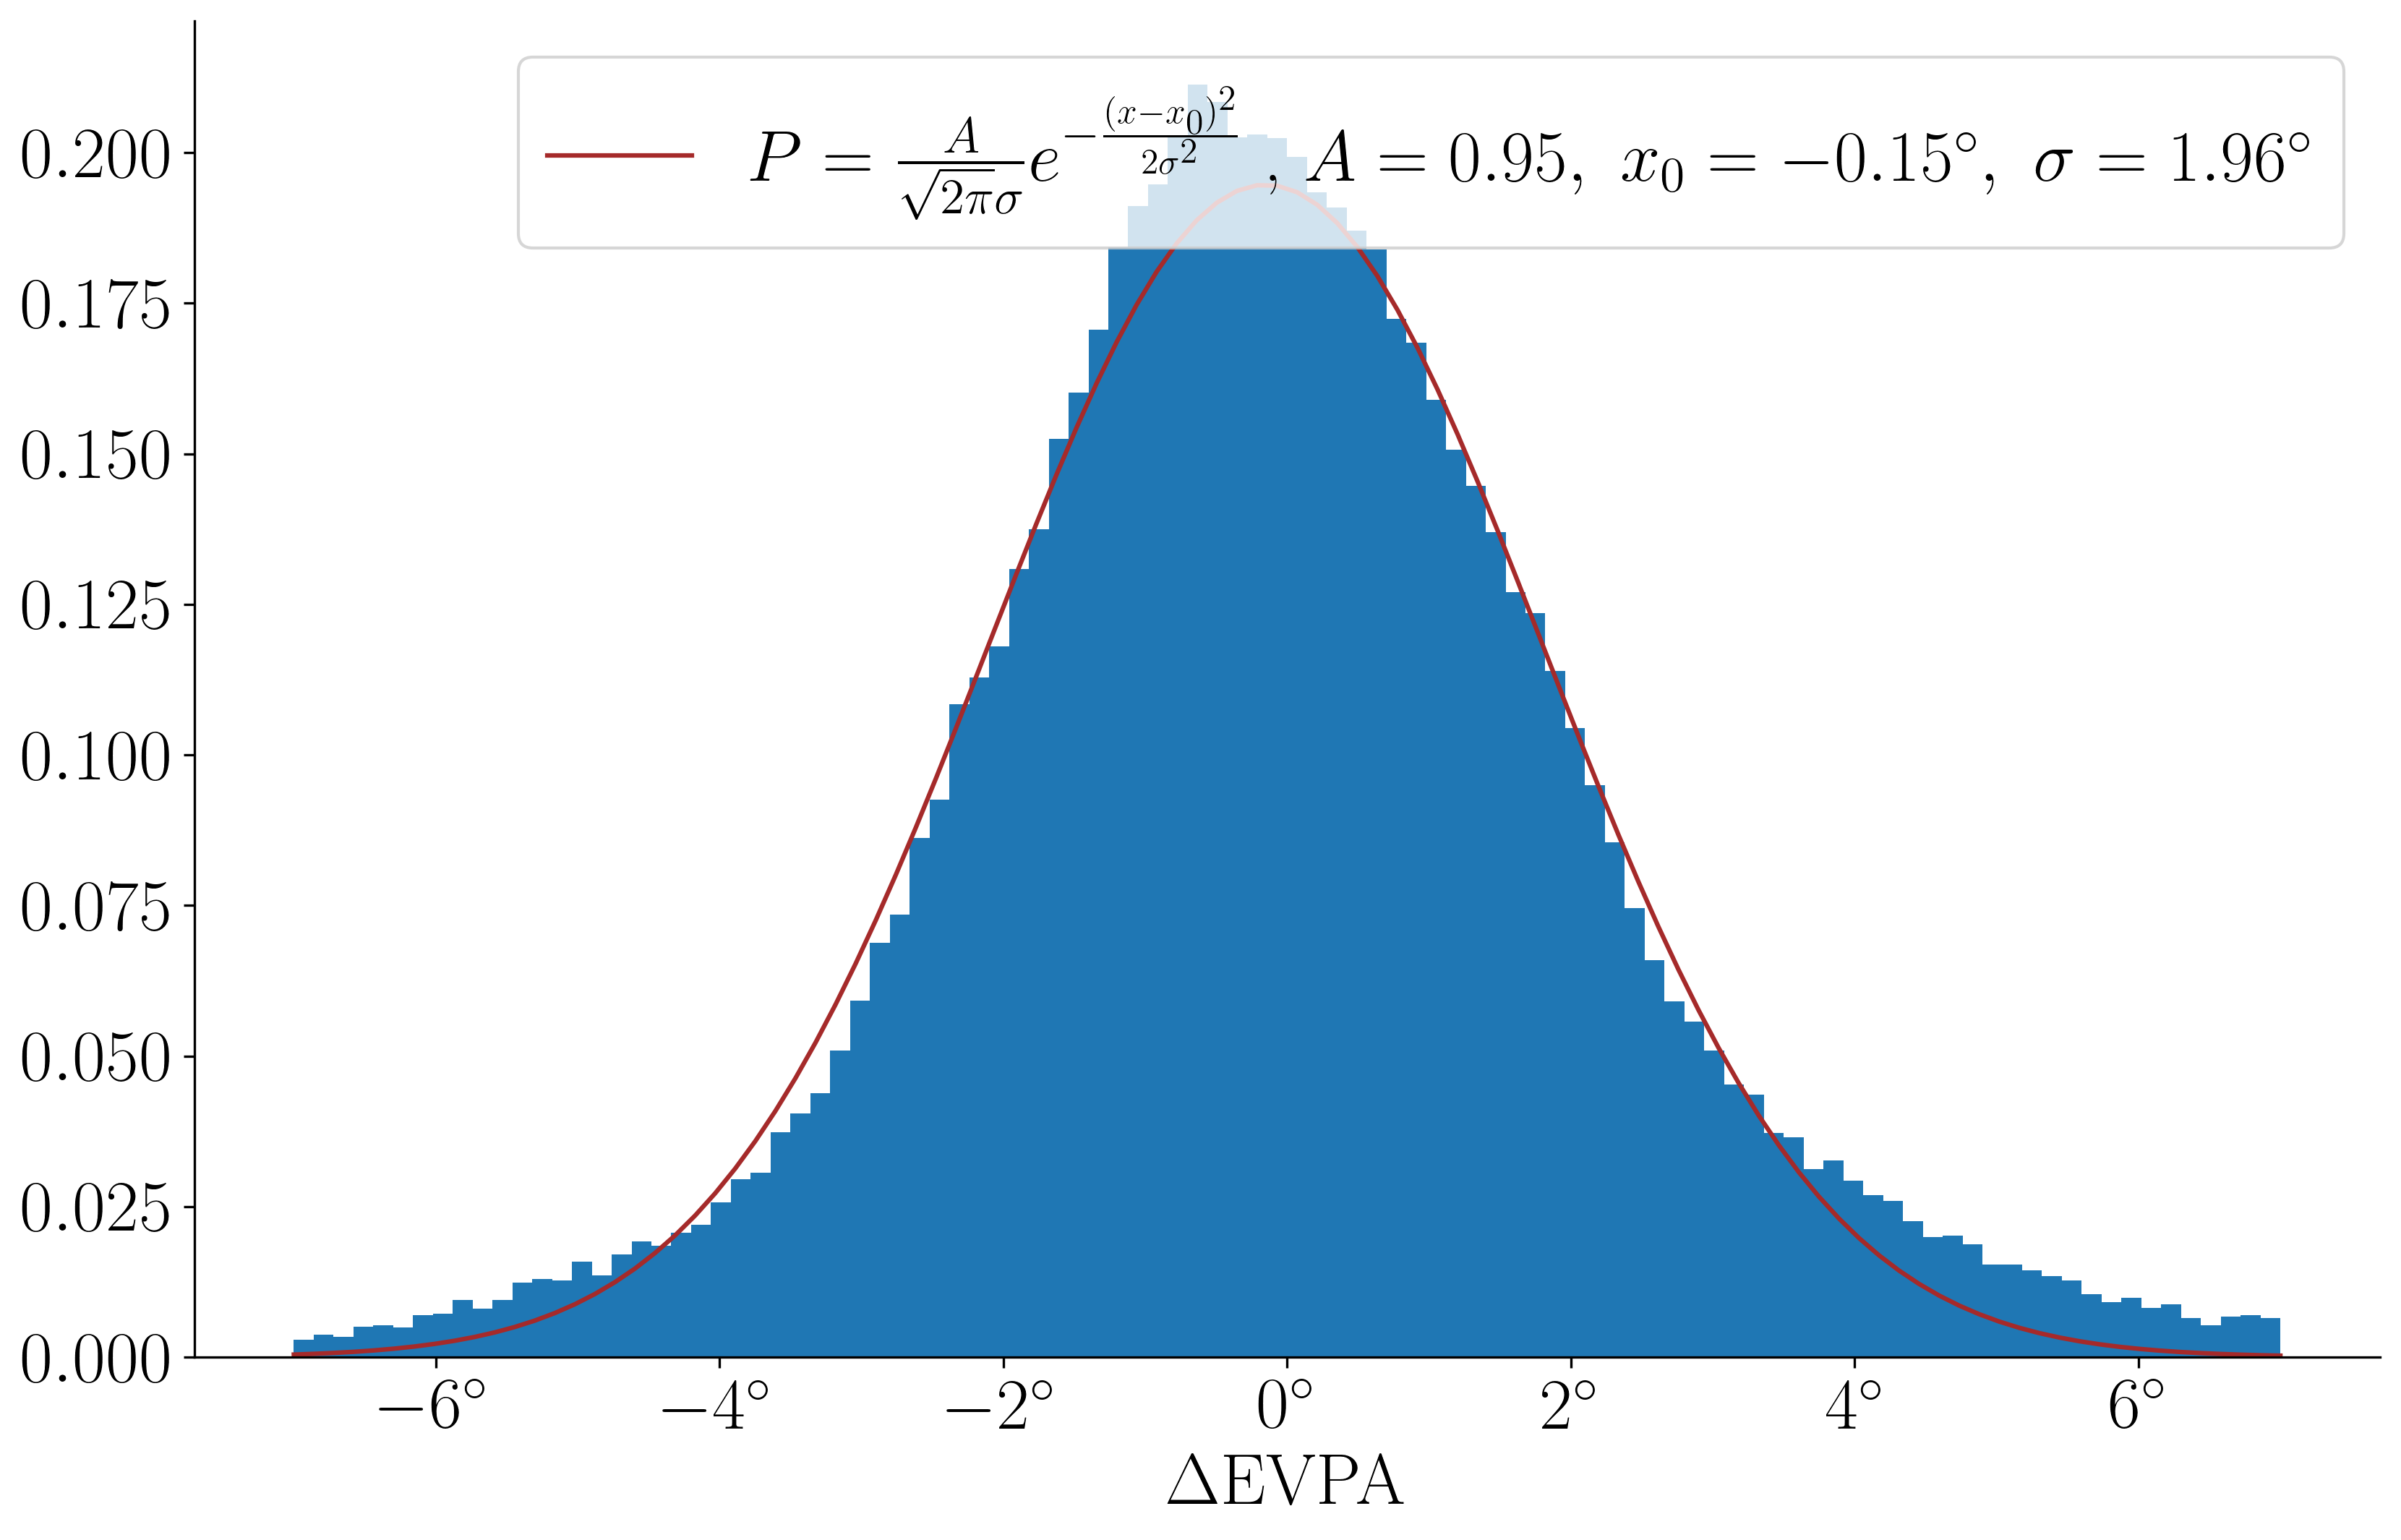

np.float64(1.9552619810762537)

In [32]:
plot_gaussian1(
    evpa_diff_with_condition.reshape(-1, 1)[:, 0] / np.pi * 180,
    bins=100,
    plot_range=(-7, 7),
    plot=True,
    initial_guess=[1, 0, 1],
    rm_nan=True,
    figsize=(13, 8),
)[0][2]

In [17]:
cor_grmhd = np.identity(64 * 64) * (_cor_grmhd_tmp_ / 180 * np.pi) ** 2

In [18]:
_cor_grmhd_tmp_

np.float64(1.9752611467515768)

In [19]:
def make_interpolator(axion_evpa_diffs_std_16phase):
    """
    给定一个 {alpha: ndarray(16,64,64)} 的字典，
    返回一个插值函数 f(alpha)，输出线性插值结果。
    """
    # 提取并排序 alpha 值
    alphas = np.array(sorted(axion_evpa_diffs_std_16phase.keys()))

    # 将数据堆叠为 (N_alpha, 16, 64, 64)
    data = np.stack([axion_evpa_diffs_std_16phase[a] for a in alphas])

    def f(alpha):
        # 若超出范围，则截断在边界
        if alpha <= alphas[0]:
            return data[0]
        if alpha >= alphas[-1]:
            return data[-1]

        # 找到相邻区间
        idx = np.searchsorted(alphas, alpha) - 1
        a0, a1 = alphas[idx], alphas[idx + 1]
        w = (alpha - a0) / (a1 - a0)

        # 线性插值
        return (1 - w) * data[idx] + w * data[idx + 1]

    return f

# Part Axion


In [20]:
def _omega(alpha):
    return alpha * (1 - alpha**2 / 2 / (2 + 1 + 1) ** 2)

In [21]:
alpha_grmhd = 0.3
omega_grmhd = _omega(alpha_grmhd)
axion_norm = 0.1  # check it
g_res = 40
gagg = np.logspace(np.log10(1 / 137.0), 2, g_res)

In [22]:
# EVPA_fit_result = np.load("./GRMHD/EVPA_fit_result.npy")  # rad

我们没有跑不同 omega 下的 axion 随 grmhd 演化的效应。因此需要把在 omega=0.4 情况下的 diffs_axion_evpa 结果 rescale 到所有的情况。使用不同 omega 时 photon ring 的半径上的 axion 强度来 rescale。

错误的，现在跑了


In [23]:
# import pandas as pd
# from scipy.interpolate import RegularGridInterpolator


# def load_and_interpolate(csv_file):
#     # 读取CSV文件
#     df = pd.read_csv(csv_file, header=None, names=["omega", "R", "f"])

#     # 获取唯一的omega和R值
#     omega_values = np.unique(df["omega"].values)
#     R_values = np.unique(df["R"].values)

#     # 创建二维插值网格
#     f_values = df.pivot(index="omega", columns="R", values="f").values

#     # 创建插值函数
#     interpolator = RegularGridInterpolator(
#         (omega_values, R_values), f_values, bounds_error=False, fill_value=None
#     )

#     def _f(omega, R):
#         # 计算插值
#         return interpolator((omega, R))

#     return _f

In [24]:
# R_photon_ring = (246 - 157) / 400 * 2 * 23.1131 / 2

In [25]:
# f_axion_norm = load_and_interpolate("NormR.csv")

## every pixel, find sigma of diffs_axion_evpa over every grmhd


In [26]:
EVPA_cos_fit_result = {}
EVPA_cos_fit_result_1d_10deg = {}
for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    EVPA_cos_fit_result[alpha] = np.load(
        f"GRMHD/data_out/EVPA_cos_fit_result_alpha={alpha}.npy"
    )
    EVPA_cos_fit_result_1d_10deg[alpha] = np.load(
        f"GRMHD/data_out/EVPA_cos_fit_result_1d_10deg_alpha={alpha}.npy"
    )

In [27]:
from utils.libanaly import fit_gaussian, fit_gaussian2

In [28]:
def b_scaling(alpha):
    return 0.03 * (alpha / 0.05) ** (7 / 4)

In [29]:
extra_phase = np.linspace(0, 2 * np.pi, 16)


def get_A_phi0_params():
    # these have different alpha results, and these 2 are mean and std of 1day evpa diff at each pixel
    A_params_dict = {}
    phi0_params_dict = {}
    for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
        # EVPA_without_axion = EVPA[alpha][:, 0, :, :]
        P_without_axion = np.sqrt(
            grmhdDataAfterImageS[alpha][:, 0, :, :, 1] ** 2
            + grmhdDataAfterImageS[alpha][:, 0, :, :, 2] ** 2
        )
        # condition = (
        #     P_without_axion > P_without_axion.max(axis=(1, 2))[:, None, None] * 0.1
        # )  # ?*64*64 and 64*64
        A_data_list = EVPA_cos_fit_result[alpha][:, :, :, 0]
        # A_data_list[A_data_list == 0] = np.nan
        phi0_data_list = EVPA_cos_fit_result[alpha][:, :, :, 1]
        # phi0_data_list[phi0_data_list == 0] = np.nan
        A_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            A_data_list,
            rm_nan=True,
            plot_failed=True,
            threshold=np.nan,
            p_value_threshold=0.001,
            bins=20,
            nomean=True,
        )
        A_params_dict[alpha] = A_params
        phi0_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            phi0_data_list,
            rm_nan=True,
            plot_failed=True,
            angle=True,
            lower_bound=-np.pi,
            upper_bound=np.pi,
            threshold=np.nan,
            p_value_threshold=0.001,
            bins=20,
            nomean=True,
        )  # change it
        phi0_params_dict[alpha] = phi0_params
    return A_params_dict, phi0_params_dict


A_params_dict, phi0_params_dict = get_A_phi0_params()

# for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
#     for i in range(64):
#         for j in range(64):
#             if np.isnan(A_params_dict[alpha][0, i, j]):
#                 A_params_dict[alpha][0, i, j] = (
#                     A_params_dict[alpha][0, i - 1, j]
#                     + A_params_dict[alpha][0, i + 1, j]
#                     + A_params_dict[alpha][0, i, j - 1]
#                     + A_params_dict[alpha][0, i, j + 1]
#                 ) / 4
#                 A_params_dict[alpha][1, i, j] = (
#                     A_params_dict[alpha][1, i - 1, j]
#                     + A_params_dict[alpha][1, i + 1, j]
#                     + A_params_dict[alpha][1, i, j - 1]
#                     + A_params_dict[alpha][1, i, j + 1]
#                 ) / 4
#             if np.isnan(phi0_params_dict[alpha][0, i, j]):
#                 phi0_params_dict[alpha][0, i, j] = (
#                     phi0_params_dict[alpha][0, i - 1, j]
#                     + phi0_params_dict[alpha][0, i + 1, j]
#                     + phi0_params_dict[alpha][0, i, j - 1]
#                     + phi0_params_dict[alpha][0, i, j + 1]
#                 ) / 4
#                 phi0_params_dict[alpha][1, i, j] = (
#                     phi0_params_dict[alpha][1, i - 1, j]
#                     + phi0_params_dict[alpha][1, i + 1, j]
#                     + phi0_params_dict[alpha][1, i, j - 1]
#                     + phi0_params_dict[alpha][1, i, j + 1]
#                 ) / 4
# np.save("GRMHD/data_out/A_params_dict_nonan.npy", A_params_dict, allow_pickle=True)
# np.save(
#     "GRMHD/data_out/phi0_params_dict_nonan.npy", phi0_params_dict, allow_pickle=True
# )

# raise KeyboardInterrupt

np.save("GRMHD/data_out/A_params_dict.npy", A_params_dict, allow_pickle=True)
np.save("GRMHD/data_out/phi0_params_dict.npy", phi0_params_dict, allow_pickle=True)
A_params_interpolator = make_interpolator(A_params_dict)
phi0_params_interpolator = make_interpolator(phi0_params_dict)


def axion_evpa_diffs_16phase_1(alpha):
    # 这里给的是振幅为ga=axion_norm*1/2/pi， 2pi g a=2pi g f axion_norm=axion_norm 时的结果，所以左右除以axion_norm后就是2pi g f=1时的结果。最终求限制的时候，2pi g f从1/137到2，对应了2pi g a=2pi g b f=这个值*(1/137,2)*b
    # 因此在那里要乘以gagg[g]再乘以b_scaling(alpha)，或者把b在这里乘掉。b越小，导致理论变化值越小，限制越弱。或者说理论预言： 2pi g b f=1时会导致1/2/pi的偏转 观测偏转小于1，证明2pi g b f小于2pi，2pi g f小于2pi/b，所以b越小限制越差
    A_params = A_params_interpolator(alpha)
    phi0_params = phi0_params_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )

    _axion_evpa_diffs_16phase_tmp_1 = np.zeros(
        (
            16,
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[1],
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[2],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_diffs_16phase_tmp_1[i] = (
            constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
        )  # *gagg[g]

    return _axion_evpa_diffs_16phase_tmp_1


def axion_evpa_diffs_16phase_2(alpha):
    A_params = A_params_interpolator(alpha)
    phi0_params = phi0_params_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )

    _axion_evpa_diffs_16phase_tmp_2 = np.zeros(
        (
            16,
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[1],
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[2],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]

        _axion_evpa_diffs_16phase_tmp_2[i] = (
            constant1_axion
            * A_params[0]
            * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
        )  # *gagg[g]

    return _axion_evpa_diffs_16phase_tmp_2


def axion_evpa_diffs_std_16phase(alpha):
    A_params = A_params_interpolator(alpha)
    phi0_params = phi0_params_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )

    _axion_evpa_diffs_std_16phase_tmp = np.zeros(
        (
            16,
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[1],
            EVPA_cos_fit_result[list(EVPA_cos_fit_result.keys())[0]].shape[2],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_diffs_std_16phase_tmp[i] = np.sqrt(
            np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
            + np.power(
                constant1_axion
                * A_params[0]
                * np.cos(ep + phi0_params[0])
                * phi0_params[1],
                2,
            )
        )
    return _axion_evpa_diffs_std_16phase_tmp


# for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
#     for i in range(extra_phase.shape[0]):
#         # 需要确定，使用统计结果还是挑选某个特定时间？
#         ep = extra_phase[i]
#         _axion_evpa_diffs_16phase_tmp_1[i] = (
#             constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
#         )  # *gagg[g]

#         _axion_evpa_diffs_16phase_tmp_2[i] = (
#             constant1_axion
#             * A_params[0]
#             * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
#         )  # *gagg[g]

#         _axion_evpa_diffs_std_16phase_tmp[i] = np.sqrt(
#             np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
#             + np.power(
#                 constant1_axion
#                 * A_params[0]
#                 * np.cos(ep + phi0_params[0])
#                 * phi0_params[1],
#                 2,
#             )
#         )
#     axion_evpa_diffs_16phase_1[alpha] = _axion_evpa_diffs_16phase_tmp_1
#     axion_evpa_diffs_16phase_2[alpha] = _axion_evpa_diffs_16phase_tmp_2
#     axion_evpa_diffs_std_16phase[alpha] = _axion_evpa_diffs_std_16phase_tmp

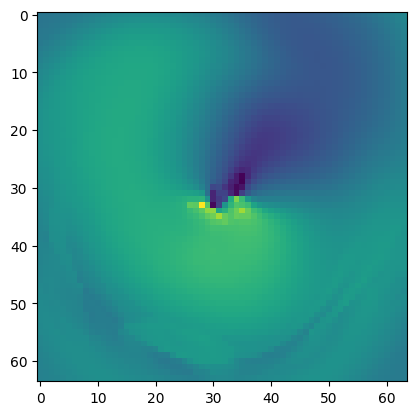

In [30]:
_x = np.zeros((64, 64))
for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    _x += axion_evpa_diffs_16phase_1(alpha)[0]
plt.imshow(_x)

In [31]:
# extra_phase = np.linspace(0, 2 * np.pi, 16)


# # 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(ep+phi0)/axion_norm*gagg[g]
# # first calc 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(ep+phi0)/axion_norm
# # and define 2*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)/axion_norm

# condition = (P_without_axion > threshold) * condition2to9  # ?*64*64 and 64*64

# # caution!!! amp should be set
# constant1_axion = (
#     2
#     * np.sin(0.112411 * omega_grmhd / 2 * 24)
#     * np.sin(0.112411 * omega_grmhd / 2 * 6)
#     / (0.112411 * omega_grmhd / 2 * 6)
#     / axion_norm
# )

# diffs_axion_evpa_t = np.zeros((16, EVPA_fit_result.shape[1], EVPA_fit_result.shape[2]))
# diffs_axion_evpa_std_t = np.zeros(
#     (16, EVPA_fit_result.shape[1], EVPA_fit_result.shape[2])
# )

# A_data_list = deepcopy(EVPA_fit_result[:, :, :, 0]) * condition
# A_data_list[A_data_list == 0] = np.nan
# phi0_data_list = deepcopy(EVPA_fit_result[:, :, :, 1]) * condition
# phi0_data_list[phi0_data_list == 0] = np.nan

In [32]:
# def fit_gaussian(
#     data_list,
#     bins_list=[40, 30, 20],
#     initial_guess=[1, 0, 1],
#     rm_nan=False,
#     maxfev=5000000,
#     output=True,
# ):
#     _data = deepcopy(data_list)
#     if rm_nan == True:
#         _data = _data[np.isfinite(_data)]

#     fit_success = False

#     if output:
#         print("------------------fit start-----------------------")

#     for bins in bins_list:
#         if _data.shape[0] < bins:
#             if output:
#                 print("badfit, bins>len(data)")
#             continue
#         hist, bin_edges = np.histogram(_data, bins=bins, density=True)
#         bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
#         initial_guess[0] = 1  # np.shape(_data)[0]
#         initial_guess[1] = bin_centers[np.argmax(hist)]
#         initial_guess[2] = np.std(_data)
#         try:
#             params, covariance = curve_fit(
#                 _gaussian_noAmp, bin_centers, hist, maxfev=maxfev  # p0=initial_guess,
#             )
#         except Exception as e:
#             if output:
#                 print("badfit, error", e)
#             continue
#         # params=np.asarray(params)
#         # covariance=np.asarray(covariance)
#         c1 = abs(covariance[1][1]) / abs(params[1])
#         # c2 = abs(covariance[2][2]) / abs(params[2])
#         # if output:
#         #     print(c1, c2)
#         if c1 < 1:  # and c2 < 1:
#             fit_success = True
#             break
#         else:
#             if output:
#                 print("badfit, cov")
#     if not fit_success:
#         params = np.zeros((3))
#         covariance = np.zeros((3, 3))
#         params[:] = np.nan
#         covariance[:] = np.nan
#     if output:
#         print("fit complete!")
#     return params, covariance


# def fit_gaussian_params(
#     data_list,
#     bins_list=[40, 30, 20],
#     initial_guess=[1, 0, 1],
#     rm_nan=False,
#     maxfev=5000000,
#     output=True,
# ):
#     params, _ = fit_gaussian(
#         data_list,
#         bins_list=bins_list,
#         initial_guess=initial_guess,
#         rm_nan=rm_nan,
#         maxfev=maxfev,
#         output=output,
#     )
#     return params

In [33]:
# # 4min
# A_params = np.apply_along_axis(fit_gaussian_params, 0, A_data_list, rm_nan=True)
# phi0_params = np.apply_along_axis(
#     fit_gaussian_params, 0, phi0_data_list, rm_nan=True
# )  # change it

In [34]:
# # np.save("A_params",A_params)
# # np.save("phi0_params",phi0_params)
# A_params = np.load("A_params.npy")  # amplitude, mean, stddev
# phi0_params = np.load("phi0_params.npy")

In [35]:
# amp = EVPA_fit_result[51, :, :, 0]
# phi0 = EVPA_fit_result[51, :, :, 1]
# for i in range(extra_phase.shape[0]):
#     ep = extra_phase[i]
#     diffs_axion_evpa_t[i] = constant1_axion * amp * np.sin(ep + phi0)  # *gagg[g]
#     diffs_axion_evpa_std_t[i] = np.sqrt(
#         np.power(constant1_axion * np.sin(ep + phi0) * A_params[2], 2)
#         + np.power(constant1_axion * amp * np.cos(ep + phi0) * phi0_params[2], 2)
#     )
# diffs_axion_evpa = np.mean(diffs_axion_evpa_t, axis=0)  # rad
# diffs_axion_evpa_std = np.mean(diffs_axion_evpa_std_t, axis=0)  # rad

In [36]:
# A_params.shape

In [37]:
# np.save("./Plot/diffs_axion_evpa_std.npy", diffs_axion_evpa_std)

In [38]:
# np.save("./Plot/diffs_axion_evpa.npy", diffs_axion_evpa)

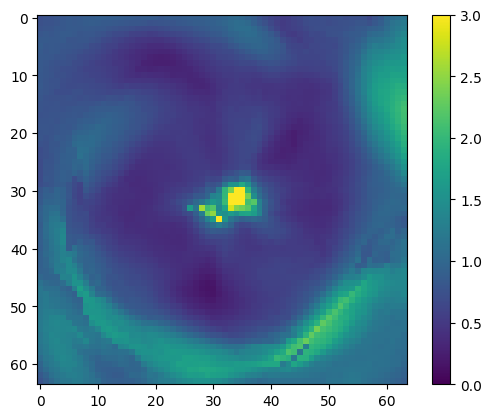

In [39]:
plt.imshow(np.mean(axion_evpa_diffs_std_16phase(0.3), axis=0) / np.pi * 180)
plt.colorbar()
plt.clim(0, 3)

In [40]:
# figure, ax = plt.subplots(figsize=(30, 30))
# Plot_Background(figure, ax, A_params[1] / np.pi * 180)

1d


In [41]:
# # 141,360,3
# EVPA_fit_result_1d = np.load("./GRMHD/EVPA_fit_result_1d.npy")  # rad

In [42]:
extra_phase = np.linspace(0, 2 * np.pi, 16)
# these have different alpha results, and these 2 are mean and std of 1day evpa diff at each pixel


def get_A_phi0_1d_params():
    A_params_dict = {}
    phi0_params_dict = {}
    for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
        A_data_list = EVPA_cos_fit_result_1d_10deg[alpha][:, :, 0]
        A_data_list[A_data_list == 0] = np.nan
        phi0_data_list = EVPA_cos_fit_result_1d_10deg[alpha][:, :, 1]
        phi0_data_list[phi0_data_list == 0] = np.nan
        A_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            A_data_list,
            rm_nan=True,
            plot_failed=False,
            threshold=0.2,
            p_value_threshold=0.001,
            bins=20,
        )
        A_params_dict[alpha] = A_params
        phi0_params = np.apply_along_axis(
            fit_gaussian2,
            0,
            phi0_data_list,
            rm_nan=True,
            plot_failed=False,
            angle=True,
            lower_bound=-np.pi,
            upper_bound=np.pi,
            threshold=0.2,
            p_value_threshold=0.001,
            bins=20,
        )  # change it
        phi0_params_dict[alpha] = phi0_params
    return A_params_dict, phi0_params_dict


A_params_1d_dict, phi0_params_1d_dict = get_A_phi0_1d_params()
np.save("GRMHD/data_out/A_params_1d_dict.npy", A_params_1d_dict, allow_pickle=True)
np.save(
    "GRMHD/data_out/phi0_params_1d_dict.npy", phi0_params_1d_dict, allow_pickle=True
)
A_params_1d_interpolator = make_interpolator(A_params_1d_dict)
phi0_params_1d_interpolator = make_interpolator(phi0_params_1d_dict)


def axion_evpa_1d_diffs_16phase_1(alpha):
    A_params = A_params_1d_interpolator(alpha)
    phi0_params = phi0_params_1d_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )
    _axion_evpa_1d_diffs_16phase_tmp_1 = np.zeros(
        (
            16,
            EVPA_cos_fit_result_1d_10deg[
                list(EVPA_cos_fit_result_1d_10deg.keys())[0]
            ].shape[1],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_1d_diffs_16phase_tmp_1[i] = (
            constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
        )  # *gagg[g]
    return _axion_evpa_1d_diffs_16phase_tmp_1


def axion_evpa_1d_diffs_16phase_2(alpha):
    A_params = A_params_1d_interpolator(alpha)
    phi0_params = phi0_params_1d_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )
    _axion_evpa_1d_diffs_16phase_tmp_2 = np.zeros(
        (
            16,
            EVPA_cos_fit_result_1d_10deg[
                list(EVPA_cos_fit_result_1d_10deg.keys())[0]
            ].shape[1],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_1d_diffs_16phase_tmp_2[i] = (
            constant1_axion
            * A_params[0]
            * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
        )  # *gagg[g]
    return _axion_evpa_1d_diffs_16phase_tmp_2


def axion_evpa_1d_diffs_std_16phase(alpha):
    A_params = A_params_1d_interpolator(alpha)
    phi0_params = phi0_params_1d_interpolator(alpha)
    # caution!!! amp should be set
    constant1_axion = (
        2
        * np.sin(0.112411 * _omega(alpha) / 2 * 24)
        * np.sin(0.112411 * _omega(alpha) / 2 * 6)
        / (0.112411 * _omega(alpha) / 2 * 6)
        / axion_norm
    )
    _axion_evpa_1d_diffs_std_16phase_tmp = np.zeros(
        (
            16,
            EVPA_cos_fit_result_1d_10deg[
                list(EVPA_cos_fit_result_1d_10deg.keys())[0]
            ].shape[1],
        )
    )
    for i in range(extra_phase.shape[0]):
        # 需要确定，使用统计结果还是挑选某个特定时间？
        ep = extra_phase[i]
        _axion_evpa_1d_diffs_std_16phase_tmp[i] = np.sqrt(
            np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
            + np.power(
                constant1_axion
                * A_params[0]
                * np.cos(ep + phi0_params[0])
                * phi0_params[1],
                2,
            )
        )
    return _axion_evpa_1d_diffs_std_16phase_tmp


# for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
#     # caution!!! amp should be set
#     constant1_axion = (
#         2
#         * np.sin(0.112411 * _omega(alpha) / 2 * 24)
#         * np.sin(0.112411 * _omega(alpha) / 2 * 6)
#         / (0.112411 * _omega(alpha) / 2 * 6)
#         / axion_norm
#     )
#     _axion_evpa_1d_diffs_16phase_tmp_1 = np.zeros(
#         (16, EVPA_cos_fit_result_1d_10deg[alpha].shape[1])
#     )
#     _axion_evpa_1d_diffs_16phase_tmp_2 = np.zeros(
#         (16, EVPA_cos_fit_result_1d_10deg[alpha].shape[1])
#     )
#     _axion_evpa_1d_diffs_std_16phase_tmp = np.zeros(
#         (16, EVPA_cos_fit_result_1d_10deg[alpha].shape[1])
#     )
#     for i in range(extra_phase.shape[0]):
#         # 需要确定，使用统计结果还是挑选某个特定时间？
#         ep = extra_phase[i]
#         _axion_evpa_1d_diffs_16phase_tmp_1[i] = (
#             constant1_axion * A_params[0] * np.sin(ep + phi0_params[0])
#         )  # *gagg[g]
#         _axion_evpa_1d_diffs_16phase_tmp_2[i] = (
#             constant1_axion
#             * A_params[0]
#             * np.sin(ep + 0.112411 * _omega(alpha) / 2 * 24 * 5 + phi0_params[0])
#         )  # *gagg[g]
#         _axion_evpa_1d_diffs_std_16phase_tmp[i] = np.sqrt(
#             np.power(constant1_axion * np.sin(ep + phi0_params[0]) * A_params[1], 2)
#             + np.power(
#                 constant1_axion
#                 * A_params[0]
#                 * np.cos(ep + phi0_params[0])
#                 * phi0_params[1],
#                 2,
#             )
#         )
#     axion_evpa_1d_diffs_16phase_1[alpha] = _axion_evpa_1d_diffs_16phase_tmp_1
#     axion_evpa_1d_diffs_16phase_2[alpha] = _axion_evpa_1d_diffs_16phase_tmp_2
#     axion_evpa_1d_diffs_std_16phase[alpha] = _axion_evpa_1d_diffs_std_16phase_tmp

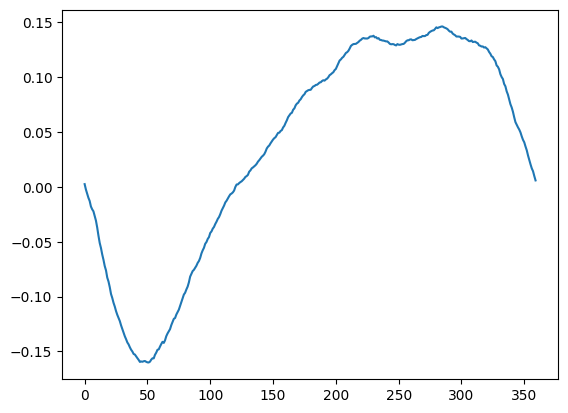

In [43]:
_x = np.zeros((360,))
for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    _x += axion_evpa_1d_diffs_16phase_1(alpha)[0, :]
plt.plot(_x)

In [44]:
# diffs_axion_evpa_t_1d = np.zeros((16, EVPA_fit_result_1d.shape[1]))
# diffs_axion_evpa_std_t_1d = np.zeros((16, EVPA_fit_result_1d.shape[1]))

# A_data_list_1d = deepcopy(EVPA_fit_result_1d[:, :, 0])
# A_data_list_1d[A_data_list_1d == 0] = np.nan
# phi0_data_list_1d = deepcopy(EVPA_fit_result_1d[:, :, 1])
# phi0_data_list_1d[phi0_data_list_1d == 0] = np.nan

In [45]:
# 2min
# A_params_1d=np.apply_along_axis(fit_gaussian_params,0,A_data_list_1d,rm_nan=True)
# phi0_params_1d=np.apply_along_axis(fit_gaussian_params,0,phi0_data_list_1d,rm_nan=True) # change it

In [46]:
# # np.save("A_params_1d",A_params_1d)
# # np.save("phi0_params_1d",phi0_params_1d)
# A_params_1d = np.load("A_params_1d.npy")  # amplitude, mean, stddev
# phi0_params_1d = np.load("phi0_params_1d.npy")

In [47]:
# amp_1d = EVPA_fit_result_1d[51, :, 0]
# phi0_1d = EVPA_fit_result_1d[51, :, 1]
# for i in range(extra_phase.shape[0]):
#     ep = extra_phase[i]
#     diffs_axion_evpa_t_1d[i] = (
#         constant1_axion * amp_1d * np.sin(ep + phi0_1d)
#     )  # *gagg[g]
#     diffs_axion_evpa_std_t_1d[i] = np.sqrt(
#         np.power(constant1_axion * np.sin(ep + phi0_1d) * A_params_1d[2], 2)
#         + np.power(
#             constant1_axion * amp_1d * np.cos(ep + phi0_1d) * phi0_params_1d[2], 2
#         )
#     )
# diffs_axion_evpa_1d = np.mean(diffs_axion_evpa_t_1d, axis=0)  # rad
# diffs_axion_evpa_std_1d = np.mean(diffs_axion_evpa_std_t_1d, axis=0)  # rad

# EXPERIMENT


In [48]:
import pickle
import numpy as np
import matplotlib
import os
import argparse
import numpy as np
from copy import deepcopy
from scipy.interpolate import griddata, interp2d
from scipy import integrate, optimize
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter


def plotting_script(xarray, yarray, name="test"):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.set_xscale("log")
    ax2 = ax.twiny()
    ax2.set_xscale("log")
    ax2.set_ylim(-2, 6)
    ax.set_yticks([-2, -1, 0, 1, 2, 3, 4, 5, 6])
    ax.set_yticklabels(["-2", "-1", "0", "1", "2", "3", "4", "5", "6"], size=20)
    ax.set_ylabel(r"$\log_{10}(c)$", size=30)
    ax2.set_xticks([0.1, 0.45])
    ax2.set_xticklabels(["0.1", "0.45"], size=20)
    ax2.set_xlabel(r"$ \alpha $", size=30)
    ax2.set_xlim(0.0486495, 4.86495)
    ax.set_xlim(1e-19, 1e-21)
    ax.set_xticks([1e-21, 1e-20, 1e-19])
    ax.set_xticklabels(["-21", "-20", "-19"], size=20)
    ax.set_xlabel(r"$\log_{10}(m_a/\mathrm{eV})$", size=30)
    ax2.plot(xarray, yarray, "black")
    ax2.plot([np.max(xarray), np.max(xarray)], [yarray[-1], 6], "black")
    ax2.plot([np.min(xarray), np.min(xarray)], [yarray[0], 6], "black")

    xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
    ax2.fill_between(xarray, yarray, 6, ls="-", lw=2, fc=xcolor[0], alpha=1)
    plt.savefig(f"M_all/new_static/{name}.pdf", dpi=600)


def get_inv(M):
    u, s, v = np.linalg.svd(M)
    return np.dot(u / s, u.T)

# Final


In [49]:
import scipy.stats as stats

In [50]:
def vonmises_mean(d1evpaarr):
    # d1evpaarr is from -0.5pi to 0.5pi
    kappa_fit, mu_fit, _ = stats.vonmises.fit(d1evpaarr * 2)  # 只拟合 kappa 和 mu
    return mu_fit / 2

In [51]:
def topset_rank(data_cor, data_std, condition_good):
    sum_of_pixels = np.zeros(1572)
    for i in range(4):
        rmnan_times = np.nan_to_num(data_cor[i] / data_std[i].reshape(4096, 1), nan=0)
        sum_of_pixels += np.sum(
            ((rmnan_times)[np.where((condition_good).reshape(4096))]) ** 2,
            axis=0,
        )
    return sum_of_pixels

In [52]:
condition = np.load("./EHT-Imaging/data_out/condition.npy", allow_pickle=True)

In [63]:
theta_mean = []
theta_std = []
P_mean = []
I_mean = []
theta_cor = []
badset = []
theta_data_vonmises_list = []
resolution = 64
xy_coord = [(i, j) for i in range(resolution) for j in range(resolution)]


num = 0
data_cor_list = []
for day in [95, 96, 100, 101]:
    with np.load(f"./EHT-Imaging/data_out/{day}.npz") as data:
        theta_mean.append(data["arr_0"])  # rad
        theta_std.append(data["arr_1"])  # rad
        P_mean.append(data["arr_2"] * 6.54737e12)  # ?这个哪来的
        I_mean.append(data["arr_3"] * 6.54737e12)
        # P_mean.append(data['arr_2'])

    All_data = np.load(f"./EHT-Imaging/data_out/{day}_all_data.npy")
    theta_data = 0.5 * np.arctan2(All_data[:, :, :, 2], All_data[:, :, :, 1])  # rad
    theta_data[np.isnan(theta_data)] = 0
    theta_vonmises_mean = np.apply_along_axis(vonmises_mean, 0, theta_data)
    theta_data_vonmises_list.append(
        CircleCalc.circle_sub_evpa(theta_data, theta_vonmises_mean)
        + theta_vonmises_mean
    )

    theta_data = (
        CircleCalc.circle_sub_evpa(theta_data, theta_mean[num]) + theta_mean[num]
    )
    # theta_data=theta_data*180./np.pi # degree

    data_cor = np.zeros((64 * 64, All_data.shape[0]))
    for x in range(len(xy_coord)):
        i, j = xy_coord[x]
        if (
            theta_mean[num][i][j] == 0
            and theta_std[num][i][j] == 0
            or np.isnan(theta_mean[num][i][j])
            or np.isnan(theta_std[num][i][j])
        ):
            badset.append(i * resolution + j)
        # data_cor[x] = (theta_data[i][j]-theta_mean[num][i][j])
        if np.isfinite(theta_mean[num][i][j]):
            pass
        data_cor[x] = CircleCalc.circle_sub_evpa(
            theta_data[:, i, j], theta_mean[num][i, j]
        )
    data_cor_list.append(data_cor)
    num += 1

# sum_of_pixels = topset_rank(data_cor_list, theta_std, condition)

for num in range(4):

    cor_data = np.dot(data_cor_list[num], data_cor_list[num].T) / All_data.shape[0]
    # cor_data = (
    #     np.dot(
    #         data_cor_list[num][:, np.argsort(sum_of_pixels)[:786]],
    #         data_cor_list[num][:, np.argsort(sum_of_pixels)[:786]].T,
    #     )
    #     / 786
    # )

    theta_cor.append(cor_data)

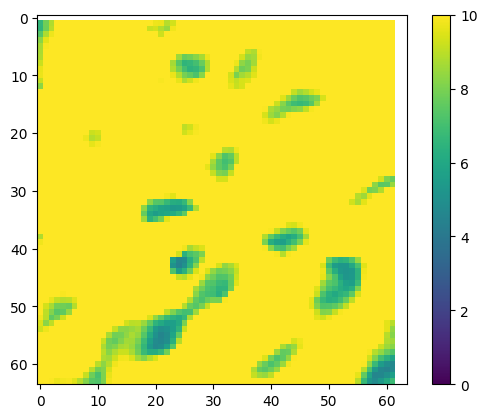

In [54]:
plt.imshow(theta_std[2] / np.pi * 180)
plt.colorbar()
plt.clim(0, 10)

In [55]:
# np.save("./EHT-Imaging/data_out/topset_rank_786.npy", np.argsort(sum_of_pixels)[:786])

In [56]:
# def gaussian2(x, *param):
#     mean = param[0]
#     sigma = param[1]
#     amplitude = param[2]
#     return (
#         amplitude
#         / np.sqrt(2.0 * np.pi * sigma * sigma)
#         * np.exp(-np.power(x - mean, 2.0) / 2.0 / sigma / sigma)
#     )

In [57]:
# def fit_gaussian2(d1evpaarr, bins_i=4):
#     counts, bins = np.histogram(d1evpaarr, bins=10 * bins_i)  # 10*(4)
#     # counts,bins =re_loc(counts,bins)
#     xarray = np.array([(bins[i] + bins[i + 1]) / 2 for i in range(len(bins) - 1)])
#     try:
#         popt, pcov = optimize.curve_fit(
#             gaussian2, xarray, counts, p0=[vonmises_mean(d1evpaarr), 1, 786]
#         )  # ,maxfev=50000,gtol=1e-10
#     except Exception as e:
#         print(f"badfit, error", e)
#         return np.array([np.nan, np.nan, np.nan])
#     if abs(pcov[0][0]) > abs(popt[0]) or abs(pcov[1][1]) > abs(popt[1]):
#         print(f"badfit")
#         return np.array([np.nan, np.nan, np.nan])
#     else:
#         return np.array([popt[0], np.abs(popt[1]), popt[2]])

In [ ]:
# std_786 = []
# mean_786 = []
# theta_cor = []
# num_786 = 786
# for num in range(4):
#     print(num)
#     theta_data_786 = (
#         theta_data_vonmises_list[num]
#         .reshape(1572, 4096)
#         .T[:, np.argsort(sum_of_pixels)[:num_786]]
#     )
#     tmpres = np.apply_along_axis(
#         fit_gaussian2,
#         1,
#         theta_data_786,
#         plot_failed=False,
#         angle=True,
#         lower_bound=-np.pi / 2,
#         upper_bound=np.pi / 2,
#         threshold=0.2,
#         bins=100,
#     )
#     mean_786.append(tmpres[:, 0])
#     std_786.append(tmpres[:, 1])
#     cor_data = CircleCalc.circle_sub_evpa(theta_data_786.T, tmpres[:, 0]).T
#     theta_cor.append(np.dot(cor_data, cor_data.T) / num_786)
# np.save("./EHT-Imaging/data_out/std_786.npy", std_786, allow_pickle=True)

0


NameError: name 'sum_of_pixels' is not defined

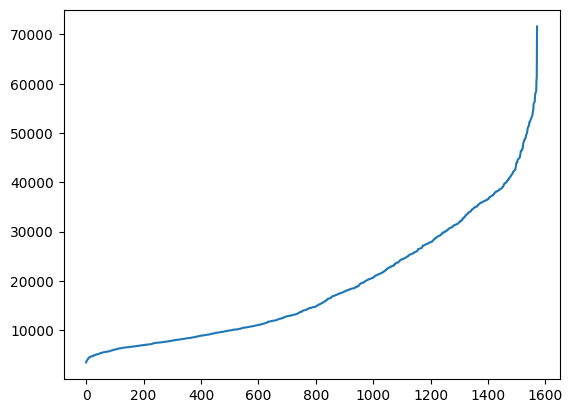

In [ ]:
plt.plot(sum_of_pixels[np.argsort(sum_of_pixels)])

In [ ]:
theta_mean[2].reshape(-1)[45 * 64 + 31]

np.float64(-1.043334284371979)

In [ ]:
mean_786[2][45 * 64 + 31]

np.float64(-1.052230869619028)

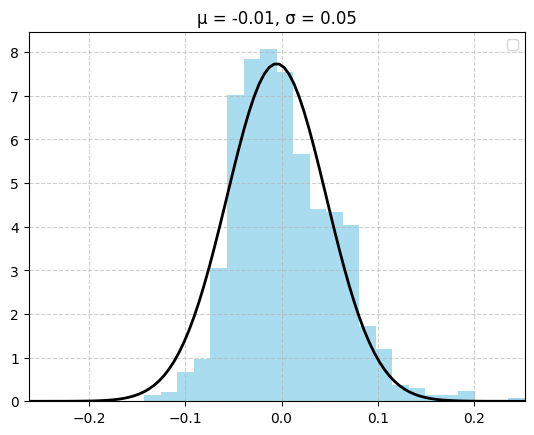

In [ ]:
mean, sigma = fit_gaussian2(
    data_cor_list[3][45 * 64 + 31][np.argsort(sum_of_pixels)[:786]],
    bins=30,
    threshold=0.2,
)
plot_gaussian(
    data_cor_list[3][45 * 64 + 31][np.argsort(sum_of_pixels)[:786]],
    bins=30,
    # plot_range=(-np.pi / 2, np.pi / 2),
    mean=mean,
    sigma=sigma,
)

In [68]:
def fastxtMinvx(x, M):
    L = cho_factor(M, lower=True)
    y = cho_solve(L, x)
    return np.dot(x, y)

In [ ]:
# f_axion_norm(0.1, R_photon_ring) / f_axion_norm(0.45, R_photon_ring)

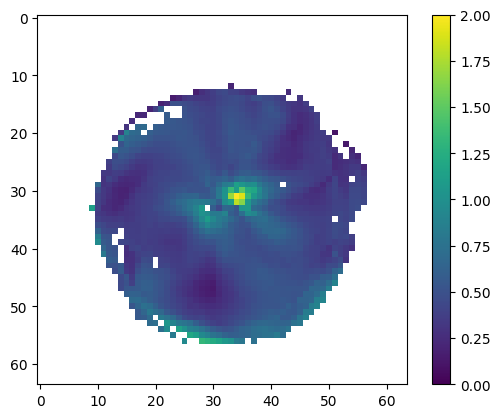

In [ ]:
plt.imshow(np.mean(axion_evpa_diffs_std_16phase(0.3), axis=0) / np.pi * 180)
plt.colorbar()
plt.clim(0, 2)

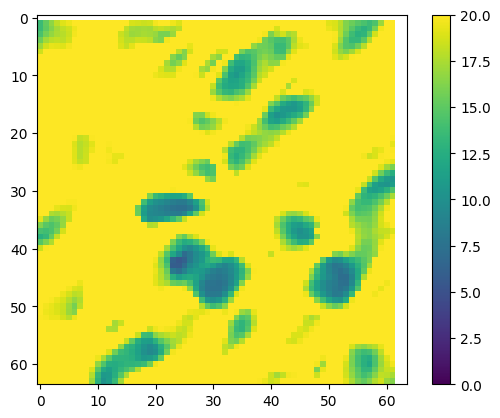

In [ ]:
plt.imshow(
    np.sqrt(theta_std[3] * theta_std[3] + theta_std[2] * theta_std[2]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

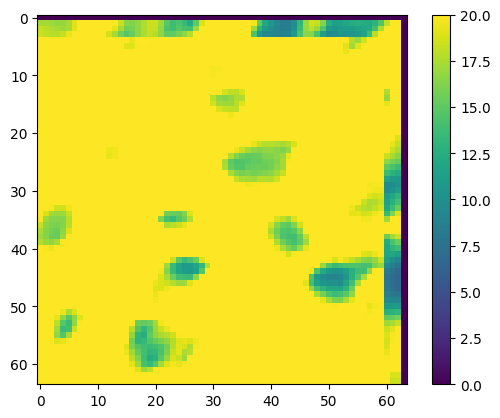

In [ ]:
# old
plt.imshow(
    np.sqrt(theta_std[3] * theta_std[3] + theta_std[2] * theta_std[2]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

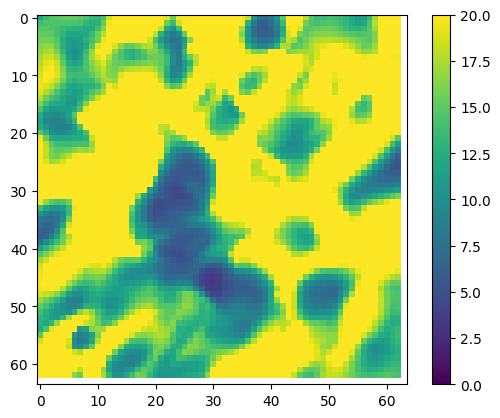

In [ ]:
plt.imshow(
    np.sqrt(theta_std[0] * theta_std[0] + theta_std[1] * theta_std[1]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

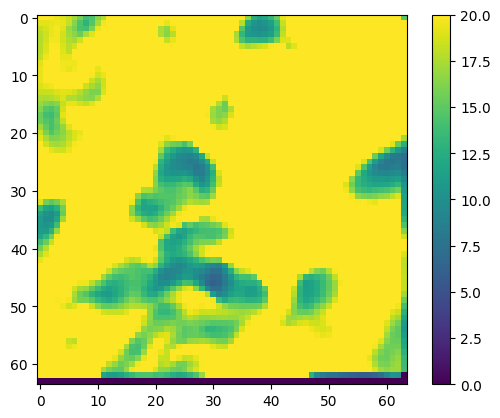

In [ ]:
# old
plt.imshow(
    np.sqrt(theta_std[0] * theta_std[0] + theta_std[1] * theta_std[1]) / np.pi * 180
)
plt.colorbar()
plt.clim(0, 20)

In [ ]:
if not os.path.exists("Results/figure"):
    os.makedirs("Results/figure")
if not os.path.exists("Results/data"):
    os.makedirs("Results/data")

In [ ]:
# plot_gaussian1(
#     theta_data_vonmises_list[num].reshape(1572, 4096).T[45 * 64 + 31],
#     bins=100,
#     plot_range=(-1.5 - 1.26, 1.5 - 1.26),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 15),
# )

In [ ]:
# plot_gaussian1(
#     theta_data_786[45 * 64 + 31],
#     bins=100,
#     plot_range=(-1.5 - 1.26, 1.5 - 1.26),
#     plot=True,
#     initial_guess=[1, 0, 1],
#     rm_nan=True,
#     figsize=(16, 15),
# )

In [ ]:
# plt.imshow(std_786[2].reshape(64, 64) / np.pi * 180)

In [ ]:
# (
#     np.sqrt(np.diag(theta_cor[0] + theta_cor[1] + theta_cor[2] + theta_cor[3]))
#     / np.sqrt(std_786[0] ** 2 + std_786[1] ** 2 + std_786[2] ** 2 + std_786[3] ** 2)
# )[45 * 64 + 31]

In [ ]:
# plt.imshow(
#     (
#         np.sqrt(np.diag(theta_cor[0] + theta_cor[1] + theta_cor[2] + theta_cor[3]))
#         / np.sqrt(std_786[0] ** 2 + std_786[1] ** 2 + std_786[2] ** 2 + std_786[3] ** 2)
#     ).reshape(64, 64)
# )
# plt.colorbar()
# plt.clim(0.9, 2)

In [ ]:
# np.std(theta_data_vonmises_list[num].reshape(1572, 4096).T[45 * 64 + 31])

In [ ]:
# plt.plot([np.std(np.sort(theta_data_786[45 * 64 + 31])[de:-de]) for de in range(1, 20)])

In [ ]:
np.std(theta_data_786[45 * 64 + 31])

np.float64(0.12045026893499346)

In [64]:
mean_topset = [
    theta_mean[i].reshape(resolution * resolution) for i in range(len(theta_mean))
]
std_topset = [
    theta_std[i].reshape(resolution * resolution) for i in range(len(theta_std))
]

In [65]:
def get_final_cut(mode="cor_grmhd"):
    # mode: "std", "cor", "cor_grmhd"
    # Delta_theta = [CircleCalc.circle_sub_evpa(theta_mean[1],theta_mean[0]).flatten(),CircleCalc.circle_sub_evpa(theta_mean[3],theta_mean[2]).flatten()] # evpasub
    Delta_theta = [
        CircleCalc.circle_sub_evpa(mean_topset[1], mean_topset[0]),
        CircleCalc.circle_sub_evpa(mean_topset[3], mean_topset[2]),
    ]  # evpasub, 但是我们不用
    # Delta_theta = [np.zeros(resolution*resolution),np.zeros(resolution*resolution)]

    # Delta_std =[np.reshape(np.sqrt(theta_std[1]*theta_std[1]+theta_std[0]*theta_std[0]),4096),np.reshape(np.sqrt(theta_std[3]*theta_std[3]+theta_std[2]*theta_std[2]),4096)]
    Delta_std = [
        np.sqrt(std_topset[1] * std_topset[1] + std_topset[0] * std_topset[0]),
        np.sqrt(std_topset[3] * std_topset[3] + std_topset[2] * std_topset[2]),
    ]
    cor_std = np.asarray([(theta_cor[1] + theta_cor[0]), (theta_cor[3] + theta_cor[2])])
    # cor_std = [theta_cor[1],theta_cor[2]]
    # print(theta_cor[1][1550][1500])

    # generate badset
    print("generating badset...")
    badset_with_large_delta = []  # deepcopy(badset)
    # _tmp_axion_evpa_diffs_16phase_ = np.zeros((64, 64))
    # for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    #     _tmp_axion_evpa_diffs_16phase_ += np.sum(
    #         axion_evpa_diffs_16phase_1(alpha), axis=0
    #     )
    #     _tmp_axion_evpa_diffs_16phase_ += np.sum(
    #         axion_evpa_diffs_16phase_2(alpha), axis=0
    #     )
    #     _tmp_axion_evpa_diffs_16phase_ += np.sum(
    #         axion_evpa_diffs_std_16phase(alpha), axis=0
    #     )  # just for finding bad pixels
    for l in range(4):
        for i in range(resolution):
            for j in range(resolution):
                # if theta_mean[l][i][j] == 0 and theta_std[l][i][j] == 0:
                if (
                    mean_topset[l][i * resolution + j] == 0
                    and std_topset[l][i * resolution + j] == 0
                    or np.isnan(mean_topset[l][i * resolution + j])
                    or np.isnan(std_topset[l][i * resolution + j])
                ):
                    badset_with_large_delta.append(i * resolution + j)

                if condition[i][j]:
                    # if np.isnan(_tmp_axion_evpa_diffs_16phase_[i, j]):
                    #     badset_with_large_delta.append(i * resolution + j)
                    # pass
                    # for lll in range(16):
                    #     diffs_axion_evpa_std_t[lll][i, j] = 1 / 2 / np.pi  # caution
                    #     diffs_axion_evpa_std[i, j] = 1 / 2 / np.pi  # caution
                    # if i <5.5 or j <1.5:
                    #     badset.append(i*resolution+j)
                    pass
                else:
                    badset_with_large_delta.append(i * resolution + j)
            # max_delta_theta=10
            # if Delta_theta[0][i*resolution+j]>max_delta_theta or Delta_theta[1][i*resolution+j]>max_delta_theta or Delta_theta[0][i*resolution+j]<-max_delta_theta or Delta_theta[1][i*resolution+j]<-max_delta_theta:
            #     badset_with_large_delta.append(i*resolution+j)
    if mode == "std":
        for i in range(4096):
            if np.isnan(Delta_std[0][i]) or np.isnan(Delta_std[1][i]):
                badset_with_large_delta.append(i)

    badset_with_large_delta = list(set(badset_with_large_delta))
    print(len(badset_with_large_delta))
    # end generate badset
    print("start calculating final_cut...")

    def getrange():
        return [10, 15, 20, 25, 30, 35, 40, 44]
        # return range(10, 45, 1)

    g_res = 60
    final_cut = [0 for alpha in getrange()]
    # temp_sig = []
    for idx, alpha in enumerate(getrange()):
        tbadset = deepcopy(badset_with_large_delta)
        goodset = list(range(resolution * resolution))
        # c = 0.005

        _tmp_axion_evpa_diffs_16phase_ = np.zeros((64, 64))
        _tmp_axion_evpa_diffs_16phase_ += np.sum(
            axion_evpa_diffs_16phase_1(alpha / 100), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_ += np.sum(
            axion_evpa_diffs_16phase_2(alpha / 100), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_ += np.sum(
            axion_evpa_diffs_std_16phase(alpha / 100), axis=0
        )  # just for finding bad pixels

        for i in range(resolution):
            for j in range(resolution):
                if np.isnan(_tmp_axion_evpa_diffs_16phase_[i, j]):
                    tbadset.append(i * resolution + j)

        # if omega > 40:
        #     pass
        omega = _omega(alpha / 100)
        print(omega)
        # Fit_result = np.load(
        #     f"GRMHD/data_in/different_omega/{alpha/100}/EVPA_result.npy"
        # )
        # for x in range(len(xy_coord)):
        #     i = int(np.floor(x / 64))
        #     j = x % 64

        #     # * Change P_mean< : 0E9: full image.    0.1E9: 600 pixels.    0.5E9:    150 pixels.            0.9E9: 50 pixels.
        #     # dynamic_cut = 0.15*np.max(I_mean)
        #     dynamic_cut = 0.1e9
        #     if P_mean[1][i][j] < dynamic_cut:
        #         tbadset.append(x)
        #     # if (i-32)*(i-32)+(j-32)*(j-32)>16*16:
        #     #     tbadset.append(x)
        #     if Fit_result[i][j][0] == -3 and Fit_result[i][j][1] == -3:
        #         tbadset.append(x)
        tbadset = np.unique(tbadset)
        tbadset.sort()
        for x in range(len(tbadset)):
            goodset.remove(tbadset[x])
        goodsetrow = np.asarray([[x for y in goodset] for x in goodset])
        goodsetcol = np.asarray([goodset for x in goodset])
        # print(np.mean([((Fit_result[:,:,0])[x//64][x%64]/theta_std[0][x//64][x%64])**2 for x in goodset]))
        phi_0 = np.linspace(0, 2 * np.pi, 16)
        gagg = np.logspace(np.log10(1 / 137.0), 3, g_res)
        prgagg = np.zeros(g_res)
        Delta_theta_theory = [
            [np.zeros((resolution, resolution)), np.zeros((resolution, resolution))]
            for i in range(16)
        ]
        llh_axion = np.zeros((g_res, 16))
        llh_axion_g = np.zeros(g_res)
        # llh_astro = np.zeros((g_res, 16))
        # llh_astro_g = np.zeros(16)
        print(np.shape(np.asarray(cor_std[0][goodsetrow, goodsetcol])))
        # M_all=[np.asarray(cor_std)+cor_grmhd+np.diag(np.power(np.reshape(diffs_axion_evpa_std_t[i],4096),2)) for i in range(16) ]
        # M_inv = [[get_inv(np.asarray(M_all[i][0][goodsetrow,goodsetcol])),get_inv(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))] for i in range(16)]
        # np.save(f'M_inv_{omega}',M_inv)
        # np.save(f'cor_std',cor_std)
        # print(f"{np.max(M_inv)},{np.min(M_inv)}")
        # print(f"{np.max(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))},{np.min(np.asarray(M_all[i][0][goodsetrow,goodsetcol]))}")

        # amp = np.asarray(Fit_result[:, :, 0])
        # print(amp.mean(), amp.max())
        # ini_phase = np.asarray(Fit_result[:, :, 1])
        # offset = np.asarray(Fit_result[:, :, 2])  # /180*np.pi

        if mode == "std":
            cor_std_good = np.asarray(
                [np.diag(Delta_std[0]) ** 2, np.diag(Delta_std[1]) ** 2]
            )[:, goodsetrow, goodsetcol]
        else:
            cor_std_good = cor_std[:, goodsetrow, goodsetcol]

        print(np.sort(np.sqrt(np.diag(cor_std_good[0]))) / np.pi * 180)
        print(np.sort(np.sqrt(np.diag(cor_std_good[1]))) / np.pi * 180)
        if mode == "cor_grmhd":
            cor_grmhd_good = cor_grmhd[goodsetrow, goodsetcol]
            tmpCorAxion = [
                np.diag(
                    np.power(
                        np.reshape(
                            axion_evpa_diffs_std_16phase(alpha / 100)[i],
                            4096,
                        ),
                        2,
                    )
                )[goodsetrow, goodsetcol]
                for i in range(16)
            ]
        else:
            cor_grmhd_good = 0
            tmpCorAxion = [0 for i in range(16)]
        for g in range(g_res):
            # print(g)
            M_all = [
                cor_std_good
                + cor_grmhd_good
                + tmpCorAxion[i] * (gagg[g]) ** 2 * b_scaling(alpha / 100) ** 2
                for i in range(16)
            ]
            # M_inv = [[get_inv(M_all[i][0])]*2 for i in range(16)]

            for l in range(16):
                # Delta_theta_theory[l][0] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+ini_phase)/0.1*gagg[g] #?
                # Delta_theta_theory[l][1] = 2*amp*np.sin(0.112411*omega/2*24)*np.sin(0.112411*omega/2*6)/(0.112411*omega/2*6)*np.sin(phi_0[l]+0.112411*omega/2*24*5+ini_phase)/0.1*gagg[g]
                Delta_theta_theory[l][0] = (
                    axion_evpa_diffs_16phase_1(alpha / 100)[l]
                    * gagg[g]
                    * b_scaling(alpha / 100)
                )
                # Delta_theta_theory[l][0] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )  # ?
                Delta_theta_theory[l][1] = (
                    axion_evpa_diffs_16phase_2(alpha / 100)[l]
                    * gagg[g]
                    * b_scaling(alpha / 100)
                )
                # Delta_theta_theory[l][1] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + 0.112411 * omega / 2 * 24 * 5 + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )

                Delta_theta_theory[l][0] = np.reshape(Delta_theta_theory[l][0], 4096)
                Delta_theta_theory[l][1] = np.reshape(Delta_theta_theory[l][1], 4096)

                for k in range(2):
                    x_diff = np.matrix(
                        (Delta_theta_theory[l][k] - Delta_theta[k] * 0)[goodset]
                    )

                    # * Calculate with cor_std.
                    # llh_axion[g][l] +=np.exp(-(np.array(np.dot(x_diff,np.dot(M_inv[l][k],x_diff.T)))[0][0])/2.)
                    llh_axion[g][l] += np.exp(
                        -fastxtMinvx(np.asarray(x_diff)[0], M_all[l][k]) / 2.0
                    )
                    # llh_axion[g][l] +=np.exp(0)

                    # * Calculate with std.
                    # llh_axion[g][l] +=np.exp(-np.sum(x_diff*x_diff.T/(2*Delta_std[k][goodset]*Delta_std[k][goodset])))

            llh_axion_g = np.sum(llh_axion, axis=1) / 16
            # llh_astro_g = np.sum(llh_astro,axis=1)/160
            for x in range(g_res):
                if x >= g:
                    prgagg[x] += llh_axion_g[g] / g_res
        g = 0
        while prgagg[g] < prgagg[g_res - 1] * 0.95:
            g += 1
        g -= 1
        # print(prgagg[-2])
        final_cut[idx] = (prgagg[g_res - 1] * 0.95 - prgagg[g]) / (
            prgagg[g + 1] - prgagg[g]
        ) * (np.log10(gagg[g + 1]) - np.log10(gagg[g])) + np.log10(gagg[g])
        print(f"{alpha-10} is done!", final_cut[idx])

    plt.plot([alpha * 0.01 for alpha in getrange()], final_cut, "s-")
    name = mode
    plt.savefig(f"Results/figure/{name}.pdf")
    plotting_script([alpha * 0.01 for alpha in getrange()], final_cut, name)
    np.savez(
        f"Results/data/{name}",
        alphas=[alpha * 0.01 for alpha in getrange()],
        cuts=final_cut,
    )
    return final_cut

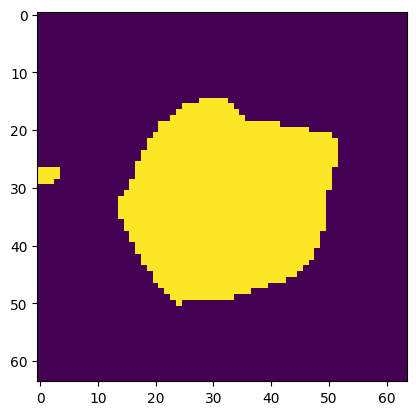

In [ ]:
# Removed an incomplete exploratory plotting call that prevented Run All.


In [36]:
theta_mean[0].shape

(64, 64)

In [ ]:
final_cut_2d = {}
final_cut_1d = {}

generating badset...
3326
start calculating final_cut...
0.09996875
(770, 770)
[ 3.41914929  3.42534642  3.59259698  3.59941924  3.6325634   3.66153699
  3.8114459   3.82670317  3.83457545  4.00520501  4.14890757  4.18003272
  4.30104995  4.30891206  4.42849314  4.47446883  4.5156486   4.61680599
  4.62535483  4.64227488  4.6634645   4.69548282  4.72015728  4.80168824
  4.84111853  4.84215438  4.85037184  4.89468179  4.94054932  4.96895901
  4.9778378   5.02759879  5.03192275  5.05703076  5.05824234  5.08464902
  5.110701    5.14670155  5.1480049   5.14807423  5.14927932  5.17571296
  5.18500129  5.22345383  5.22424928  5.25859066  5.28591843  5.30745147
  5.31720286  5.3333807   5.33479773  5.33496193  5.34633237  5.36003834
  5.37033717  5.37163344  5.3773096   5.39999405  5.41179009  5.42162914
  5.43722483  5.47064751  5.47498094  5.48291929  5.48894844  5.50832589
  5.54632799  5.56318723  5.57485975  5.57588444  5.59034488  5.62434827
  5.6443775   5.64644846  5.67804197  5.68289

<Figure size 640x480 with 0 Axes>

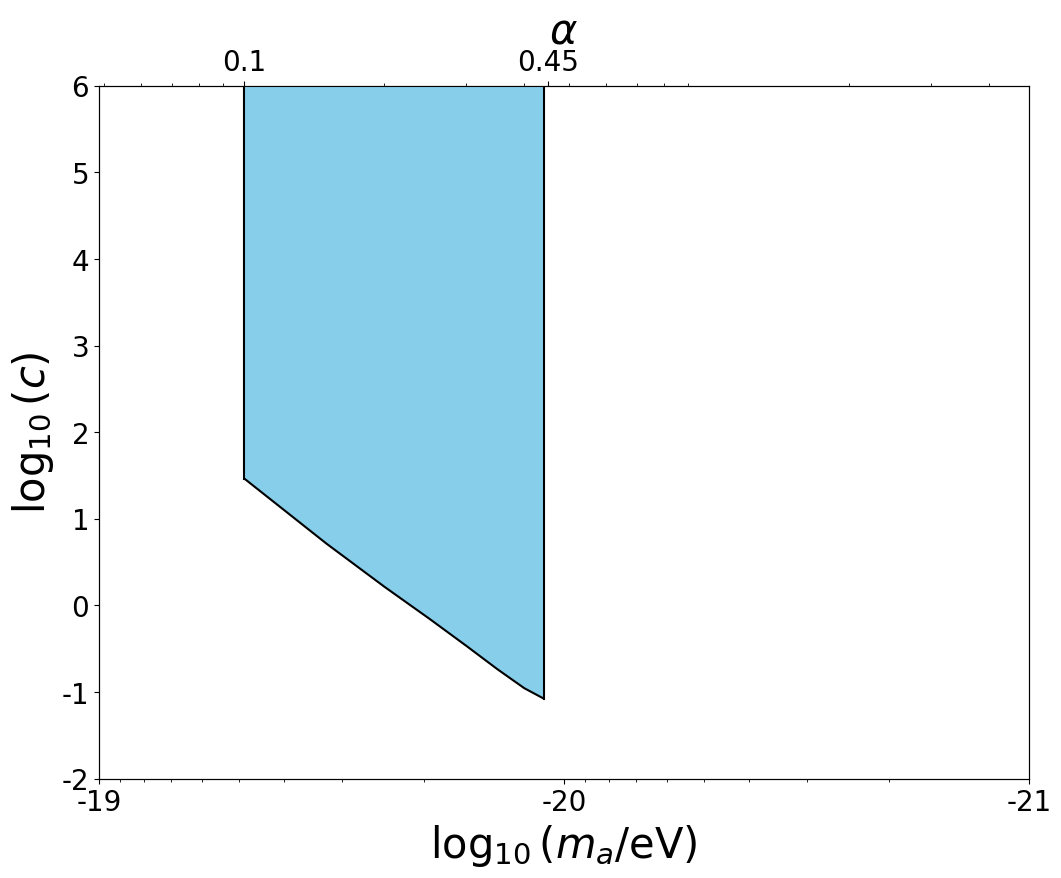

In [69]:
final_cut = get_final_cut(mode="std")
print(final_cut)
final_cut_2d["std"] = final_cut

generating badset...
3326
start calculating final_cut...
0.09996875
(770, 770)
[ 5.14078294  5.52629885  5.64740898  5.86593036  6.27118807  6.29288069
  6.37046895  6.44687043  6.59800343  6.62232015  6.69391426  6.70487912
  6.75253175  6.76202162  6.77457614  6.79667014  6.8824919   6.90754663
  6.9313912   7.11334894  7.13397471  7.16574715  7.18775234  7.20634731
  7.20696516  7.20880666  7.24157507  7.24292712  7.30385541  7.33258117
  7.37997459  7.49029986  7.56800131  7.57301474  7.60871226  7.67360544
  7.69378614  7.71599716  7.75674552  7.76425196  7.80498363  7.80576245
  7.81733174  7.83921227  7.89397551  7.90706448  7.91370571  7.94931709
  7.99405849  8.04716133  8.10539882  8.26925222  8.27429672  8.28193601
  8.30163916  8.33240256  8.360714    8.38032861  8.42156357  8.42280112
  8.45290757  8.45732349  8.58120766  8.6581405   8.73554344  8.74030945
  8.75844509  8.81801579  8.86001718  8.88072668  8.89052087  8.89459845
  8.9201592   8.9205467   8.9534159   8.96522

<Figure size 640x480 with 0 Axes>

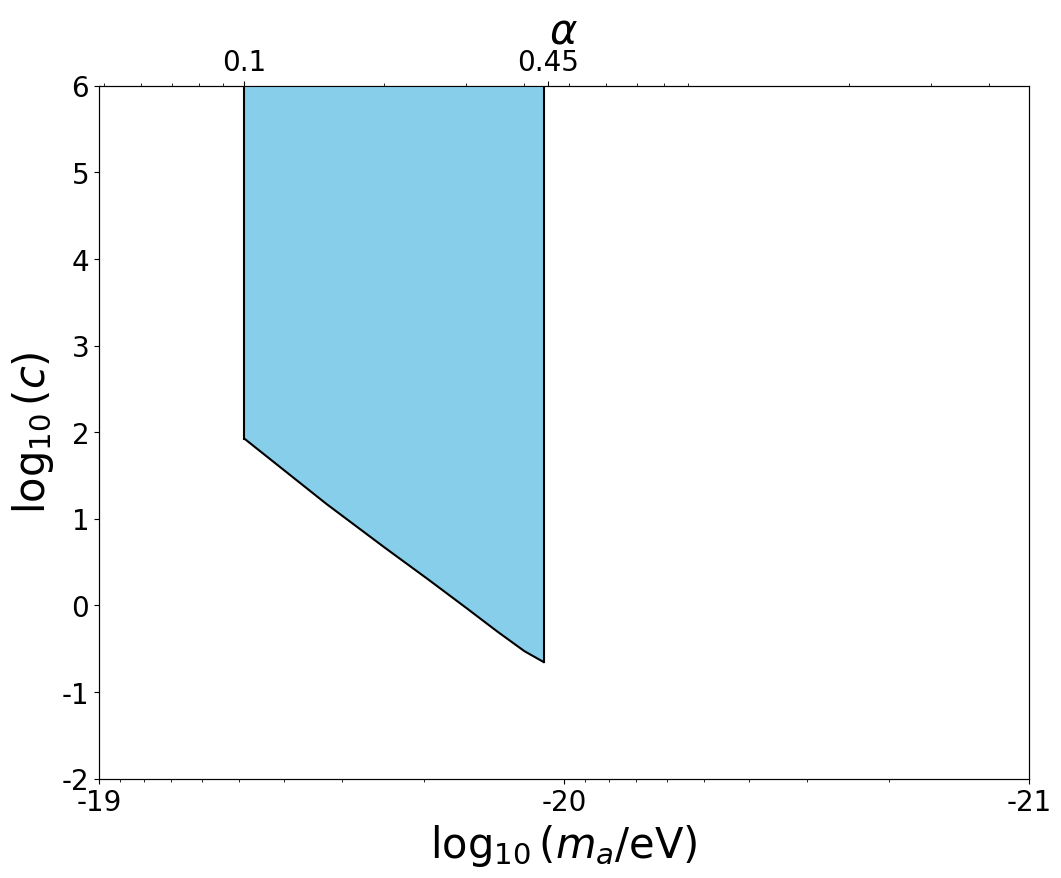

In [70]:
final_cut = get_final_cut(mode="cor")
final_cut_2d["cor"] = final_cut

generating badset...
3326
start calculating final_cut...
0.09996875
(770, 770)
[ 5.14078294  5.52629885  5.64740898  5.86593036  6.27118807  6.29288069
  6.37046895  6.44687043  6.59800343  6.62232015  6.69391426  6.70487912
  6.75253175  6.76202162  6.77457614  6.79667014  6.8824919   6.90754663
  6.9313912   7.11334894  7.13397471  7.16574715  7.18775234  7.20634731
  7.20696516  7.20880666  7.24157507  7.24292712  7.30385541  7.33258117
  7.37997459  7.49029986  7.56800131  7.57301474  7.60871226  7.67360544
  7.69378614  7.71599716  7.75674552  7.76425196  7.80498363  7.80576245
  7.81733174  7.83921227  7.89397551  7.90706448  7.91370571  7.94931709
  7.99405849  8.04716133  8.10539882  8.26925222  8.27429672  8.28193601
  8.30163916  8.33240256  8.360714    8.38032861  8.42156357  8.42280112
  8.45290757  8.45732349  8.58120766  8.6581405   8.73554344  8.74030945
  8.75844509  8.81801579  8.86001718  8.88072668  8.89052087  8.89459845
  8.9201592   8.9205467   8.9534159   8.96522

<Figure size 640x480 with 0 Axes>

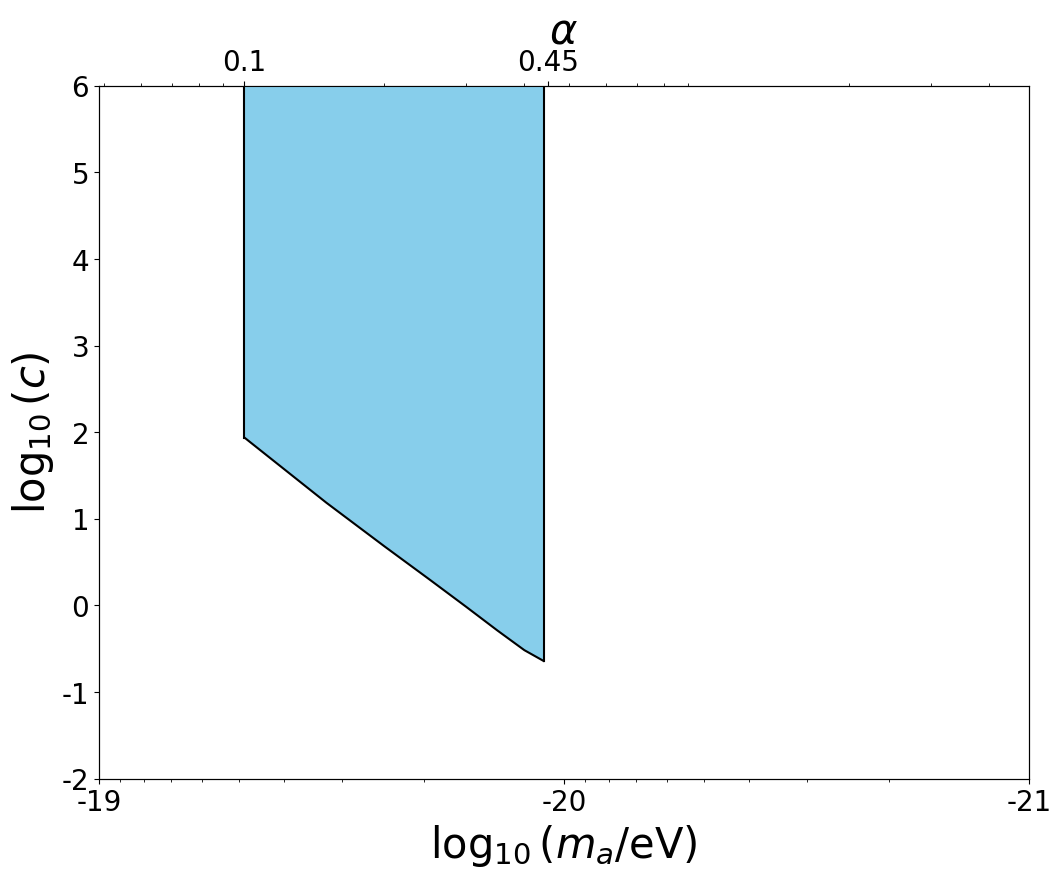

In [71]:
final_cut = get_final_cut(mode="cor_grmhd")
final_cut_2d["cor_grmhd"] = final_cut

# 1d


In [89]:
import pickle
import numpy as np
import matplotlib
import os
import argparse
import numpy as np
from copy import deepcopy

from scipy.interpolate import griddata, interp2d
from scipy import integrate, optimize
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter


def plotting_script(xarray, yarray, name):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.set_xscale("log")
    ax2 = ax.twiny()
    ax2.set_xscale("log")
    ax2.set_ylim(-2, 6)
    ax.set_yticks([-2, -1, 0, 1, 2, 3, 4, 5, 6])
    ax.set_yticklabels(["-2", "-1", "0", "1", "2", "3", "4", "5", "6"], size=20)
    ax.set_ylabel("$\log_{10}(c)$", size=30)
    ax2.set_xticks([0.1, 0.45])
    ax2.set_xticklabels(["0.1", "0.45"], size=20)
    ax2.set_xlabel(r"$ \alpha $", size=30)
    ax2.set_xlim(0.0486495, 4.86495)
    ax.set_xlim(1e-19, 1e-21)
    ax.set_xticks([1e-21, 1e-20, 1e-19])
    ax.set_xticklabels(["-21", "-20", "-19"], size=20)
    ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)
    ax2.plot(xarray, yarray, "black")
    ax2.plot([np.max(xarray), np.max(xarray)], [yarray[-1], 6], "black")
    ax2.plot([np.min(xarray), np.min(xarray)], [yarray[0], 6], "black")

    xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
    ax2.fill_between(xarray, yarray, 6, ls="-", lw=2, fc=xcolor[0], alpha=1)
    plt.savefig(f"new_static/{name}.pdf", dpi=600)


theta_mean = []
theta_std = []
theta_cor = []
resolution = 360

num = 0
for day in [95, 96, 100, 101]:
    with np.load(f"./EHT-Imaging/data_out/{day}_1d.npz") as data:
        theta_mean.append(data["arr_0"])
        theta_std.append(data["arr_1"])

    theta_data = np.load(f"./EHT-Imaging/data_out/{day}_EVPA_1d.npy")
    _tmp_sub = CircleCalc.circle_sub_evpa(theta_data, theta_mean[num])
    cor_data = np.dot(_tmp_sub.T, _tmp_sub) / _tmp_sub.shape[0]
    # cor_data = np.dot(_tmp_sub[np.argsort(sum_of_pixels)[:786],:].T,_tmp_sub[np.argsort(sum_of_pixels)[:786],:])/_tmp_sub.shape[0]
    theta_cor.append(cor_data)
    # theta_data_1d_786 = theta_data[np.argsort(sum_of_pixels)[:786]]
    # theta_data_1d_786_vonmises_mean = np.apply_along_axis(
    #     vonmises_mean, 0, theta_data_1d_786
    # )
    # theta_data_1d_786 = (
    #     CircleCalc.circle_sub_evpa(theta_data_1d_786, theta_data_1d_786_vonmises_mean)
    #     + theta_data_1d_786_vonmises_mean
    # )
    # tmpres = np.apply_along_axis(
    #     fit_gaussian2,
    #     0,
    #     theta_data_1d_786,
    #     plot_failed=False,
    #     angle=True,
    #     lower_bound=-np.pi / 2,
    #     upper_bound=np.pi / 2,
    #     bins=100,
    #     threshold=0.2,
    # )
    # theta_mean.append(tmpres[0])
    # theta_std.append(tmpres[1])
    # cor_data = CircleCalc.circle_sub_evpa(theta_data_1d_786, tmpres[0]).T
    # theta_cor.append(np.dot(cor_data, cor_data.T) / 786)
    num += 1

xy_coord = [i for i in range(resolution)]
Delta_theta = [theta_mean[1] - theta_mean[0], theta_mean[3] - theta_mean[2]]
# Delta_theta = [np.zeros(resolution),np.zeros(resolution)]
Delta_std = [
    np.sqrt(theta_std[1] * theta_std[1] + theta_std[0] * theta_std[0]),
    np.sqrt(theta_std[3] * theta_std[3] + theta_std[2] * theta_std[2]),
]
cor_std = np.asarray([theta_cor[1] + theta_cor[0], theta_cor[3] + theta_cor[2]])

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_504561/1694745571.py:24: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("$\log_{10}(c)$", size=30)
/tmp/ipykernel_504561/1694745571.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)


In [82]:
def get_final_cut_1d(mode="cor_grmhd"):
    badset = []
    # cor_std = [theta_cor[0],theta_cor[2]]
    # _tmp_axion_evpa_diffs_16phase_1d_ = np.zeros((360,))
    # for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    #     _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
    #         axion_evpa_1d_diffs_16phase_1(alpha), axis=0
    #     )
    #     _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
    #         axion_evpa_1d_diffs_16phase_2(alpha), axis=0
    #     )
    #     _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
    #         axion_evpa_1d_diffs_std_16phase(alpha), axis=0
    #     )  # just for finding bad pixels
    for i in range(resolution):
        for l in range(4):
            if (
                theta_mean[l][i] == 0
                and theta_std[l][i] == 0
                or np.isnan(theta_mean[l][i])
                or np.isnan(theta_std[l][i])
                # or np.isnan(_tmp_axion_evpa_diffs_16phase_1d_[i])
            ):
                badset.append(i)
    badset = list(set(badset))

    def getrange():
        return [10, 15, 20, 25, 30, 35, 40, 44]
        # return range(10, 45, 1)

    g_res = 60
    final_cut = [0 for alpha in getrange()]
    for idx, alpha in enumerate(getrange()):
        tbadset = deepcopy(badset)
        goodset = list(range(resolution))

        _tmp_axion_evpa_diffs_16phase_1d_ = np.zeros((360,))
        _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
            axion_evpa_1d_diffs_16phase_1(alpha / 100), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
            axion_evpa_1d_diffs_16phase_2(alpha / 100), axis=0
        )
        _tmp_axion_evpa_diffs_16phase_1d_ += np.sum(
            axion_evpa_1d_diffs_std_16phase(alpha / 100), axis=0
        )  # just for finding bad pixels
        for i in range(resolution):
            if np.isnan(_tmp_axion_evpa_diffs_16phase_1d_[i]):
                tbadset.append(i)

        # c = 0.005
        omega = _omega(alpha / 100)
        # Fit_result = np.load(
        #     f"GRMHD/data/different_omega/{omega}/EVPA_phi_10deg_result.npy"
        # )
        tbadset = list(np.unique(tbadset))
        minbadset_x = 0
        minbadset_count = 360
        for testx in range(10):
            _tbetset = deepcopy(tbadset)
            for i in range(resolution):
                if i % 10 != testx:
                    _tbetset.append(i)
            _tbetset = list(np.unique(_tbetset))
            if len(_tbetset) < minbadset_count:
                minbadset_count = len(_tbetset)
                minbadset_x = testx
        print(minbadset_x, minbadset_count)
        for i in range(resolution):
            if np.round(i % 10) != minbadset_x:  # point最多
                tbadset.append(i)
            # if Fit_result[i][0] == -3 and Fit_result[i][1] == -3:
            #     tbadset.append(i)
        tbadset = np.unique(tbadset)
        tbadset.sort()
        for x in range(len(tbadset)):
            goodset.remove(tbadset[x])
        goodsetrow = np.asarray([[x for y in goodset] for x in goodset])
        goodsetcol = np.asarray([goodset for x in goodset])
        phi_0 = np.linspace(0, 2 * np.pi, 16)
        gagg = np.logspace(np.log10(1 / 137.0), 3, g_res)
        prgagg = np.zeros(g_res)
        Delta_theta_theory = [
            [np.zeros(resolution), np.zeros(resolution)] for i in range(16)
        ]
        llh_axion = np.zeros((g_res, 16))
        llh_axion_g = np.zeros(g_res)
        # llh_astro = np.zeros((g_res, 16))
        # llh_astro_g = np.zeros(16)
        print(np.shape(np.asarray(cor_std[0][goodsetrow, goodsetcol])))
        # M_inv = [get_inv(np.asarray(cor_std[0][goodsetrow,goodsetcol])),get_inv(np.asarray(cor_std[1][goodsetrow,goodsetcol]))]
        # np.save(f'M_inv_{omega}_1d',M_inv)
        # np.save(f'cor_std_1d',cor_std)

        if mode == "std":
            cor_std_good = np.asarray(
                [np.diag(Delta_std[0]) ** 2, np.diag(Delta_std[1]) ** 2]
            )[:, goodsetrow, goodsetcol]
        else:
            cor_std_good = cor_std[:, goodsetrow, goodsetcol]
        print(np.sort(np.sqrt(np.diag(cor_std_good[0]))) / np.pi * 180)
        print(np.sort(np.sqrt(np.diag(cor_std_good[1]))) / np.pi * 180)
        if mode == "cor_grmhd":
            cor_grmhd_good = cor_grmhd[
                goodsetrow, goodsetcol
            ]  # 虽然这里的grmhd是4096x4096的矩阵，但反正取的是360x360内所以无所谓
            tmpCorAxion = [
                np.diag(np.power(axion_evpa_1d_diffs_std_16phase(alpha / 100)[i], 2))[
                    goodsetrow, goodsetcol
                ]
                for i in range(16)
            ]
        else:
            cor_grmhd_good = 0
            tmpCorAxion = [0 for i in range(16)]
        for g in range(g_res):
            M_all = [
                cor_std_good
                + cor_grmhd_good
                + tmpCorAxion[i] * (gagg[g]) ** 2 * b_scaling(alpha / 100) ** 2
                for i in range(16)
            ]
            for l in range(16):
                # amp = np.asarray(Fit_result[:, 0])
                # ini_phase = np.asarray(Fit_result[:, 1])
                # offset = np.asarray(Fit_result[:, 2])
                Delta_theta_theory[l][0] = (
                    axion_evpa_1d_diffs_16phase_1(alpha / 100)[l]
                    * gagg[g]
                    * b_scaling(alpha / 100)
                )
                Delta_theta_theory[l][1] = (
                    axion_evpa_1d_diffs_16phase_2(alpha / 100)[l]
                    * gagg[g]
                    * b_scaling(alpha / 100)
                )
                # Delta_theta_theory[l][0] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )
                # Delta_theta_theory[l][1] = (
                #     2
                #     * amp
                #     * np.sin(0.112411 * omega / 2 * 24)
                #     * np.sin(0.112411 * omega / 2 * 6)
                #     / (0.112411 * omega / 2 * 6)
                #     * np.sin(phi_0[l] + 0.112411 * omega / 2 * 24 * 5 + ini_phase)
                #     / 0.5
                #     * gagg[g]
                # )

                # Delta_theta_theory[l][0] = np.reshape(Delta_theta_theory[l][0],4096)
                # Delta_theta_theory[l][1] = np.reshape(Delta_theta_theory[l][1],4096)

                for k in range(2):
                    x_diff = np.matrix(
                        (Delta_theta_theory[l][k] - Delta_theta[k] * 0)[goodset]
                    )
                    # * Calculate with cor_std.
                    # llh_axion[g][l] +=np.exp(-(np.array(np.dot(x_diff,np.dot(M_inv[k],x_diff.T)))[0][0])/2.)
                    llh_axion[g][l] += np.exp(
                        -fastxtMinvx(np.asarray(x_diff)[0], M_all[l][k]) / 2.0
                    )

                    # * Calculate with std.
                    # llh_axion[g][l] +=np.exp(-np.sum(x_diff*x_diff.T/(2*Delta_std[k][goodset]*Delta_std[k][goodset])))

            llh_axion_g = np.sum(llh_axion, axis=1) / 16
            # llh_astro_g = np.sum(llh_astro,axis=1)/160
            for x in range(g_res):
                if x >= g:
                    prgagg[x] += llh_axion_g[g] / g_res
        g = 0
        while prgagg[g] < prgagg[g_res - 1] * 0.95:
            g += 1
        g -= 1
        final_cut[idx] = (prgagg[g_res - 1] * 0.95 - prgagg[g]) / (
            prgagg[g + 1] - prgagg[g]
        ) * (np.log10(gagg[g + 1]) - np.log10(gagg[g])) + np.log10(gagg[g])
        print(f"{idx} is done!")
    plt.plot([alpha * 0.01 for alpha in getrange()], final_cut, "s-")
    name = mode
    plt.savefig(f"Results/figure/{name}_1d.pdf")
    plotting_script([alpha * 0.01 for alpha in getrange()], final_cut, name)
    np.savez(
        f"Results/data/{name}_1d",
        alphas=[alpha * 0.01 for alpha in getrange()],
        cuts=final_cut,
    )
    return final_cut

4 339
(21, 21)
[ 3.69062198  4.18003522  4.26804095  4.66454574  4.94126771  5.11021209
  6.14169575  6.73581626  6.76860487  9.32864438 10.6624648  12.74158176
 15.49118256 16.90274391 19.31584803 22.29486375 27.78015246 29.52370701
 31.20528131 42.49630994 50.52940179]
[ 3.90206     6.79756155  7.57348199  9.12309397 11.2037045  11.56100399
 11.87527549 12.15485163 13.213661   13.77588237 13.95741198 14.68254527
 16.39191108 16.63871725 19.47399412 21.92498074 25.66305816 30.69001199
 32.66799798 49.88377008 52.7148257 ]
0 is done!
4 339
(21, 21)
[ 3.69062198  4.18003522  4.26804095  4.66454574  4.94126771  5.11021209
  6.14169575  6.73581626  6.76860487  9.32864438 10.6624648  12.74158176
 15.49118256 16.90274391 19.31584803 22.29486375 27.78015246 29.52370701
 31.20528131 42.49630994 50.52940179]
[ 3.90206     6.79756155  7.57348199  9.12309397 11.2037045  11.56100399
 11.87527549 12.15485163 13.213661   13.77588237 13.95741198 14.68254527
 16.39191108 16.63871725 19.47399412 21.92

<Figure size 640x480 with 0 Axes>

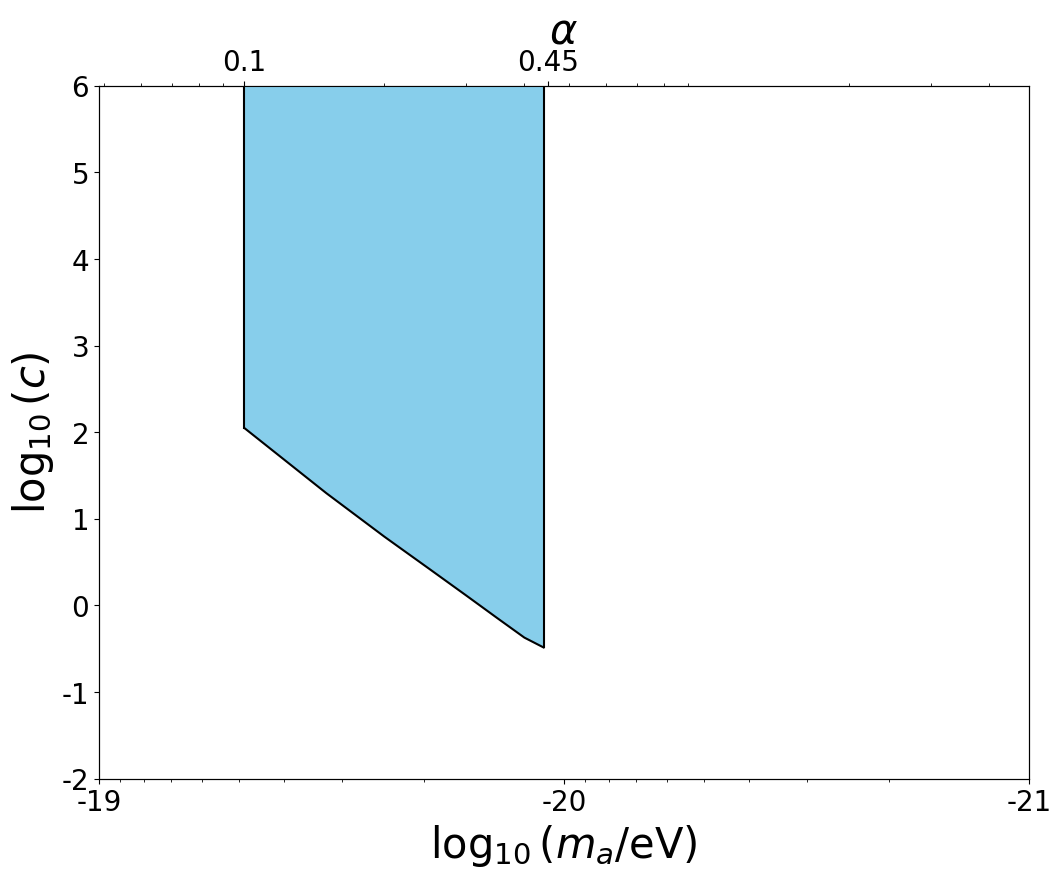

In [90]:
final_cut = get_final_cut_1d(mode="std")
final_cut_1d["std"] = final_cut

4 339
(21, 21)
[ 4.69645429  5.17341573  5.23423016  5.77488274  6.65531024  7.21815888
  8.12886385  8.77402198  9.53296273 11.53724381 12.09394275 18.54542716
 18.88825812 27.87077874 28.14041976 31.73301473 31.78907898 38.70383878
 40.37909542 43.26604552 45.33895577]
[ 4.39720052 12.83566425 13.83846314 16.22981376 16.26669657 18.56376398
 18.78502825 19.68116132 20.31892845 23.88782288 25.3644997  26.48492758
 35.55048602 36.58484663 37.64616766 38.33161595 41.63533512 41.89018094
 44.56201619 45.21694804 50.03783305]
0 is done!
4 339
(21, 21)
[ 4.69645429  5.17341573  5.23423016  5.77488274  6.65531024  7.21815888
  8.12886385  8.77402198  9.53296273 11.53724381 12.09394275 18.54542716
 18.88825812 27.87077874 28.14041976 31.73301473 31.78907898 38.70383878
 40.37909542 43.26604552 45.33895577]
[ 4.39720052 12.83566425 13.83846314 16.22981376 16.26669657 18.56376398
 18.78502825 19.68116132 20.31892845 23.88782288 25.3644997  26.48492758
 35.55048602 36.58484663 37.64616766 38.33

<Figure size 640x480 with 0 Axes>

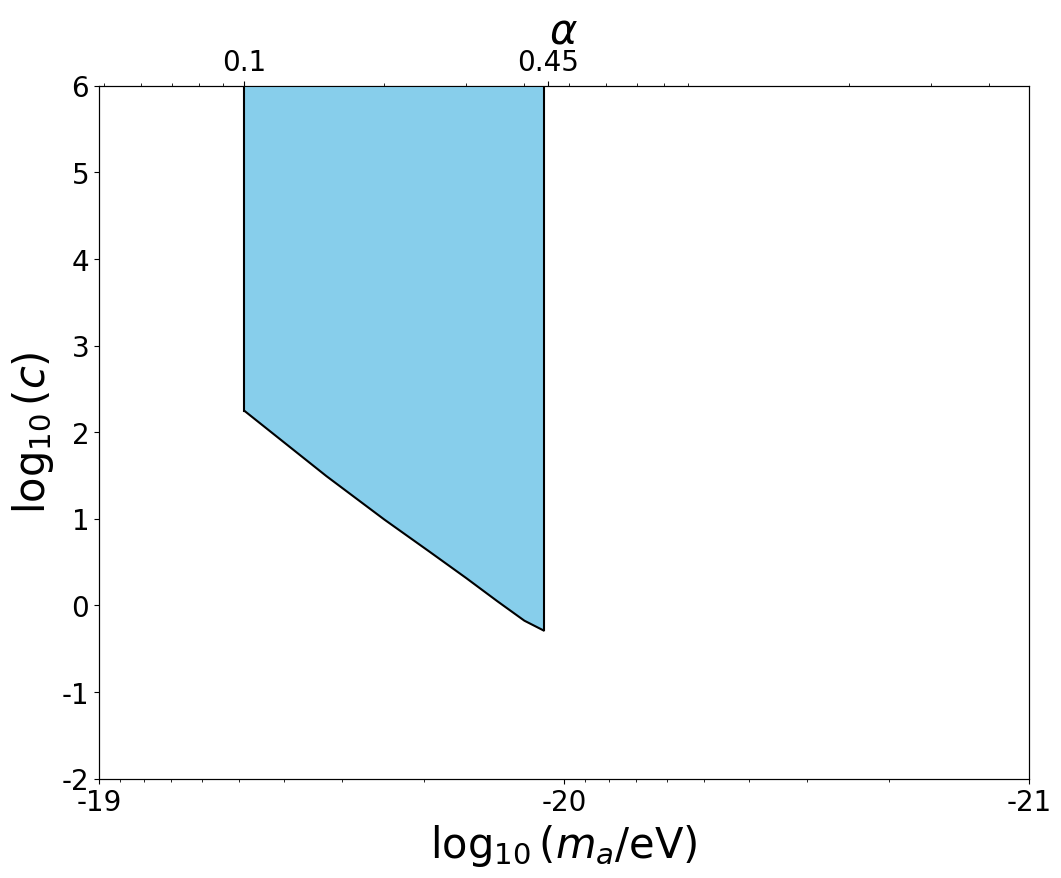

In [91]:
final_cut = get_final_cut_1d(mode="cor")
final_cut_1d["cor"] = final_cut

4 339
(21, 21)
[ 4.69645429  5.17341573  5.23423016  5.77488274  6.65531024  7.21815888
  8.12886385  8.77402198  9.53296273 11.53724381 12.09394275 18.54542716
 18.88825812 27.87077874 28.14041976 31.73301473 31.78907898 38.70383878
 40.37909542 43.26604552 45.33895577]
[ 4.39720052 12.83566425 13.83846314 16.22981376 16.26669657 18.56376398
 18.78502825 19.68116132 20.31892845 23.88782288 25.3644997  26.48492758
 35.55048602 36.58484663 37.64616766 38.33161595 41.63533512 41.89018094
 44.56201619 45.21694804 50.03783305]
0 is done!
4 339
(21, 21)
[ 4.69645429  5.17341573  5.23423016  5.77488274  6.65531024  7.21815888
  8.12886385  8.77402198  9.53296273 11.53724381 12.09394275 18.54542716
 18.88825812 27.87077874 28.14041976 31.73301473 31.78907898 38.70383878
 40.37909542 43.26604552 45.33895577]
[ 4.39720052 12.83566425 13.83846314 16.22981376 16.26669657 18.56376398
 18.78502825 19.68116132 20.31892845 23.88782288 25.3644997  26.48492758
 35.55048602 36.58484663 37.64616766 38.33

<Figure size 640x480 with 0 Axes>

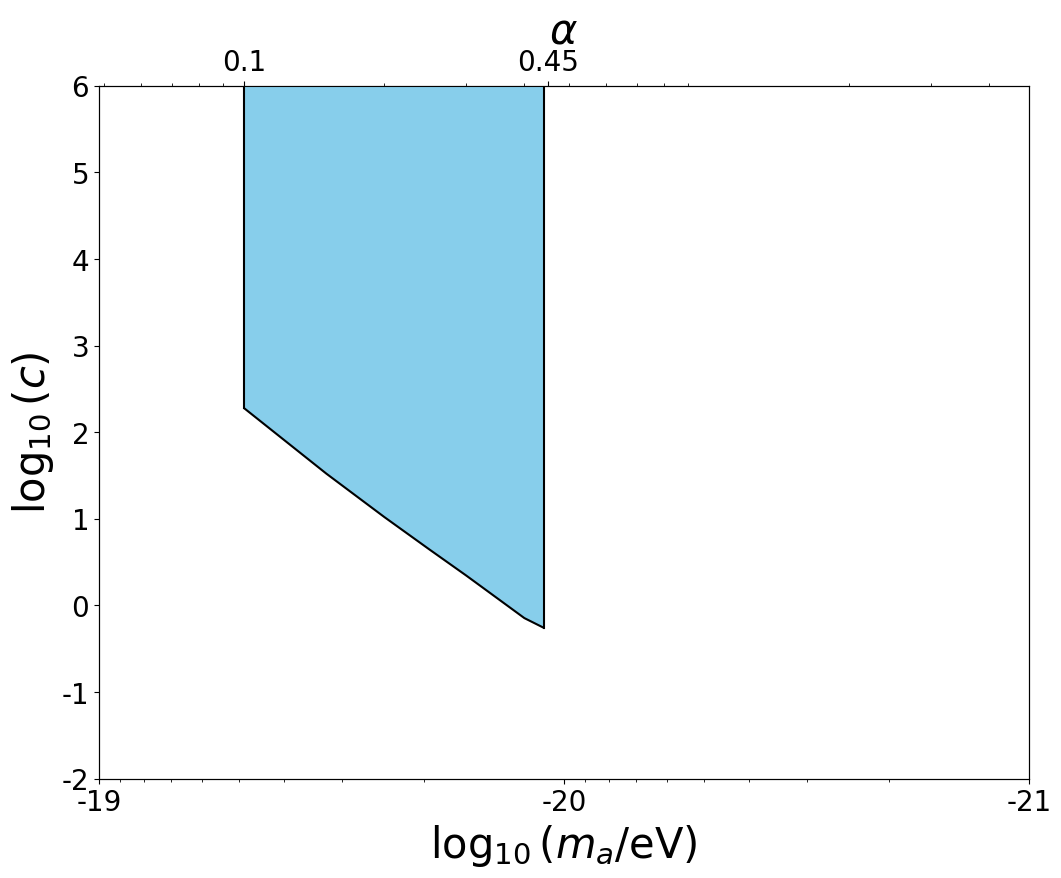

In [92]:
final_cut = get_final_cut_1d(mode="cor_grmhd")
final_cut_1d["cor_grmhd"] = final_cut

In [101]:
final_cut_2d

{'std': [np.float64(1.4638506059262306),
  np.float64(0.7154081459476058),
  np.float64(0.21625854068155603),
  np.float64(-0.15388601855622389),
  np.float64(-0.46588502912856294),
  np.float64(-0.735874690914008),
  np.float64(-0.9555445613693588),
  np.float64(-1.0741586177176319)],
 'cor': [np.float64(1.9253841283788218),
  np.float64(1.1733758800871061),
  np.float64(0.6708068456956294),
  np.float64(0.2898572682919652),
  np.float64(-0.028463436694906443),
  np.float64(-0.30158910373285586),
  np.float64(-0.5269757839214302),
  np.float64(-0.6530147075066906)],
 'cor_grmhd': [np.float64(1.9381792868509409),
  np.float64(1.1867247254655606),
  np.float64(0.6829871294609634),
  np.float64(0.30033941991802815),
  np.float64(-0.01640027863065212),
  np.float64(-0.28889465352312704),
  np.float64(-0.5160475456357865),
  np.float64(-0.6405434669268611)]}

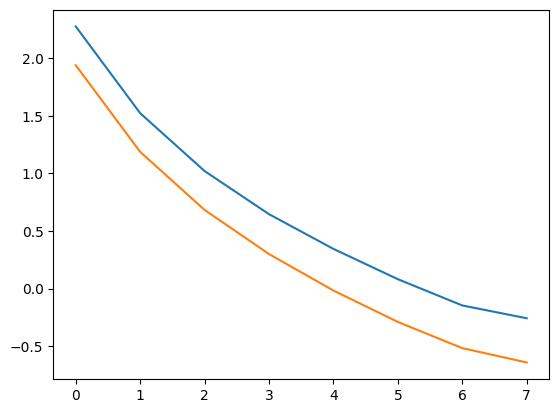

In [96]:
plt.plot(final_cut_1d["cor_grmhd"])
plt.plot(final_cut_2d["cor_grmhd"])

In [ ]:
try:
    uldict
except:
    uldict = {}

alphas = np.linspace(0.1, 0.45, 100)
ga = np.logspace(np.log10(1 / 137.0), 3, 60)

for source in ["polsolve", "DMC", "eht-imaging", "LPCAL", "Themis"]:
    # for source in ['polsolve','DMC']:
    amass = alphas * 2.05591e-20
    _x, _y = np.meshgrid(np.log10(amass), np.log10(ga * 2 * np.pi), indexing="ij")
    ul95 = calculate_ul95_with_data(source)
    uldict.update({source: ul95})

fig, ax = plt.subplots(figsize=(6, 4))
# plt.contourf(_x,_y,lnlike_xy,cmap='Greens_r',alpha=0.5,levels=[0,0.2,0.4,0.6,0.8,1],linestyles='--')
# clb = plt.colorbar()
# clb.set_label('$P/P_{max}$',size=15)


# plt.xlabel(r'$\alpha$',size=15)
plt.xlabel("$\log_{10}(m_a/eV)$", size=15)


plt.ylabel(r"$\log_{10}(c)$", size=15)
# plt.legend(handles = ctr.legend_elements()[0],labels=['95% upper limit'],loc=3)

# plt.yscale('log')
# plt.xscale('log')


# Other Limits
plt.fill_between(
    [-22, -14],
    [np.log10(8e-13 / 2 * 1e15 * 2 * np.pi)] * 2,
    [8, 8],
    ls="-",
    lw=2,
    fc="black",
    alpha=1,
    ec="black",
)
plt.fill_between(
    [-22, -14],
    [np.log10(2.6e-12 / 2 * 1e15 * 2 * np.pi)] * 2,
    [8, 8],
    ls="-",
    lw=2,
    fc="purple",
    alpha=1,
    ec="purple",
)
plt.fill_between(
    [-22, -14],
    [np.log10(3.6e-12 / 2 * 1e15 * 2 * np.pi)] * 2,
    [8, 8],
    ls="-",
    lw=2,
    fc="red",
    alpha=1,
    ec="red",
)
plt.fill_between(
    [-22, -14],
    [np.log10(5.3e-12 / 2 * 1e15 * 2 * np.pi)] * 2,
    [8, 8],
    ls="-",
    lw=2,
    fc="orange",
    alpha=1,
    ec="orange",
)
plt.fill_between(
    [-22, -14],
    [np.log10(6.6e-11 / 2 * 1e15 * 2 * np.pi)] * 2,
    [8, 8],
    ls="-",
    lw=2,
    fc="blue",
    alpha=1,
    ec="blue",
)

plt.annotate(
    "CAST",
    xy=(0.98, 0.94),
    xycoords="axes fraction",
    color="white",
    ha="right",
    size=14,
)
plt.annotate(
    "SN 1987A",
    xy=(0.98, 0.8),
    xycoords="axes fraction",
    color="black",
    ha="right",
    size=14,
)
plt.annotate(
    "NGC1275",
    xy=(0.98, 0.685),
    xycoords="axes fraction",
    color="white",
    ha="right",
    size=14,
)

plt.annotate(
    "super star clusters",
    xy=(0.98, 0.48),
    xycoords="axes fraction",
    color="red",
    ha="right",
    size=14,
)
plt.plot([-19.82, -19.82], [2.3, 4.1], lw=4, color="red")
plt.plot([-19.82], [4.1], lw=4, color="red", marker="o", markersize=12)

plt.annotate(
    "Galaxy M87",
    xy=(0.98, 0.58),
    xycoords="axes fraction",
    color="purple",
    ha="right",
    size=14,
)
plt.plot([-19.55, -19.55], [3, 3.9], lw=4, color="purple")
plt.plot([-19.55], [3.9], lw=4, color="purple", marker="o", markersize=12)


# the UL
# divede into two parts
midindex = np.argmax(amass >= 0.25 * 2.05591e-20)

ul95 = uldict["polsolve"]
plt.fill_between(
    np.log10(amass[:]),
    np.log10(ul95[:]),
    8,
    ls="-",
    lw=1,
    ec="k",
    fc="limegreen",
    alpha=1,
    label="$a_J$ = 0.99",
)
plt.fill_between(
    np.log10(amass[:midindex]),
    np.log10(ul95[:midindex]),
    8,
    ls="-",
    lw=0,
    ec="k",
    fc="green",
    hatch="///",
    alpha=1,
    label="$a_J$ = 0.8",
)
# plt.plot(np.log10([amass[midindex],amass[midindex]]),[np.log10(ul95[midindex]),6],color='k',ls='-' )
# plt.plot(np.log10([amass[-1],amass[-1]]),[np.log10(ul95[-1]),6],color='k',ls='--' )

"""
Make the border clearer!!!
"""
plt.plot([np.log10(amass[0])] * 2, [np.log10(ul95[0]), 6], "k", lw=1)
plt.plot([np.log10(amass[-1])] * 2, [np.log10(ul95[-1]), 6], "k", lw=1)
plt.plot(np.log10(amass[:]), np.log10(ul95[:]), "k", ls="-", lw=1)


# for sname in uldict:
#    ul95 = uldict[sname]
#    plt.plot(np.log10(amass[:]),np.log10(ul95[:]),color='k')

plt.fill_between(
    np.log10(amass[:]),
    np.log10(uldict["polsolve"]),
    np.log10(uldict["DMC"]),
    fc="darkgray",
    alpha=0.7,
)


plt.annotate(
    r"M87$^\star$",
    xy=(0.27, 0.65),
    xycoords="axes fraction",
    color="white",
    ha="left",
    size=16,
)

# plt.plot(np.log10(amass),np.log10(ga[z1]*2*np.pi),'r',label='$1\sigma$')
# plt.plot(np.log10(amass),np.log10(ga[z2]*2*np.pi),'orange',label='$2\sigma$')

logcmin = -2
logcmax = 6
fa = 1e15
loggmin = logcmin - np.log10(2 * np.pi * fa)
loggmax = logcmax - np.log10(2 * np.pi * fa)

plt.legend(loc=4)
plt.xlim(-21, -19)
plt.ylim(logcmin, logcmax)
plt.xticks([-21, -20, -19])


# fa
plt.annotate(
    "$f_a=10^{15}$ GeV", xy=(0.98, 0.38), xycoords="axes fraction", ha="right", size=14
)


# alpha
ax2 = ax.twiny()


ax2.set_xlim(1e-21 / 2.05591e-20, 1e-19 / 2.05591e-20)
ax2.set_xscale("log")
ax2.set_xticks([0.1, 0.45])
ax2.set_xticklabels([0.1, 0.45])
ax2.set_xlabel(r"$\alpha$", size=15)
# plt.title(source)

ax3 = ax.twinx()
ax3.set_ylim(loggmin, loggmax)


ax3.set_ylabel(r"$\log_{10}(g_{a\gamma} GeV)$", size=15)


plt.savefig("ul.pdf", bbox_inches="tight")

<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_504561/4215390943.py:23: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel("$\log_{10}(m_a/eV)$", size=15)
/tmp/ipykernel_504561/4215390943.py:23: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel("$\log_{10}(m_a/eV)$", size=15)


NameError: name 'calculate_ul95_with_data' is not defined

In [ ]:
np.sqrt(np.diag(cor_std_good[0])) / np.pi * 180

array([11.7563888 , 13.45154066, 26.38031961, 31.96265062, 21.22161131,
       18.93035074, 24.15504967, 26.65206932, 34.72027064, 19.61024197,
       14.58457443, 22.79992831, 20.15230603, 10.83766744, 10.34497303,
       11.43059054,  8.3288432 ])

In [ ]:
np.sqrt(np.diag(cor_std_good[0])) / np.pi * 180

array([11.43107396, 15.33082919, 29.91254594, 29.67396822, 24.92765656,
       19.30193136, 19.63667278, 25.56671903, 30.88545625, 34.37667603,
       23.72729762, 17.86171389, 15.92704258, 24.62061043,  7.95199034,
        9.91025657, 11.0482334 ,  9.84320908,  8.95129117, 10.55465118,
        7.60775649,  9.84547076])

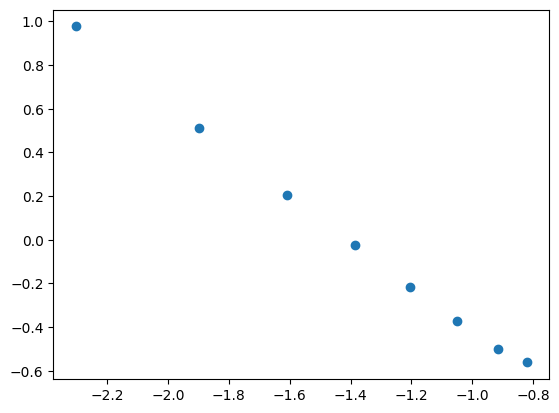

In [87]:
plt.scatter(np.log(np.array([0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44])), final_cut)

In [207]:
final_cut

[np.float64(1.5028934084145136),
 np.float64(1.3939294101656103),
 np.float64(1.2984880164334047),
 np.float64(1.219521044625946),
 np.float64(1.1228947218706897),
 np.float64(1.0545351709889288),
 np.float64(0.9830719027876236),
 np.float64(0.9113186129136752),
 np.float64(0.8586672714176375),
 np.float64(0.7920957763987064),
 np.float64(0.7399947843873623),
 np.float64(0.6892863898285836),
 np.float64(0.6364081696191491),
 np.float64(0.5964752515228422),
 np.float64(0.5433239255800661),
 np.float64(0.4976455755368914),
 np.float64(0.4546506037196992),
 np.float64(0.40851450500056574),
 np.float64(0.37482212559147965),
 np.float64(0.3284562287731632),
 np.float64(0.2921153171488353),
 np.float64(0.2554134588560792),
 np.float64(0.21612976050799518),
 np.float64(0.1850722515333471),
 np.float64(0.1482043316761318),
 np.float64(0.11782979958308852),
 np.float64(0.08324602656325561),
 np.float64(0.05424944300450993),
 np.float64(0.030452466188061765),
 np.float64(-0.0037480913606893432),

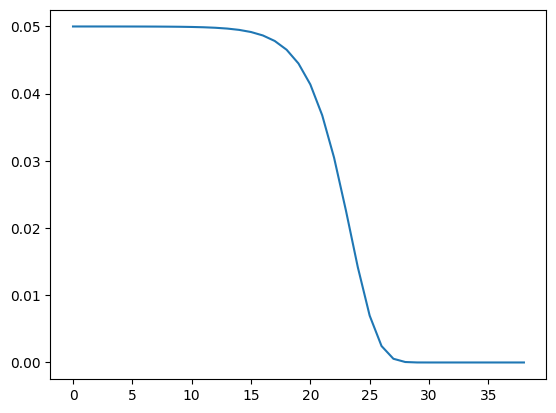

In [231]:
plt.plot(np.diff(prgagg))

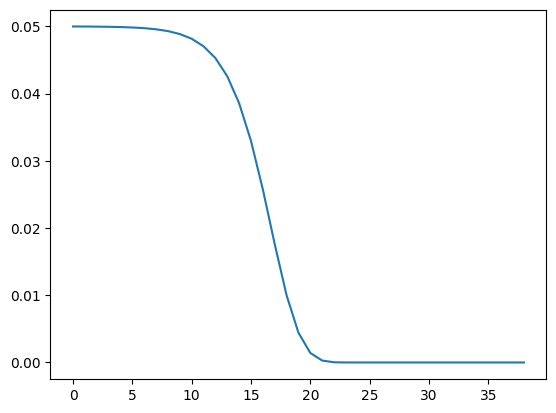

In [228]:
plt.plot(np.diff(prgagg))

In [79]:
final_cut1 = np.load("Results/data/cor_grmhd_1d.npz")
final_cut2 = np.load("Results/data/cor_grmhd.npz")

<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_222742/2604238203.py:9: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("$\log_{10}(c)$", size=30)
/tmp/ipykernel_222742/2604238203.py:17: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)


<Figure size 640x480 with 0 Axes>

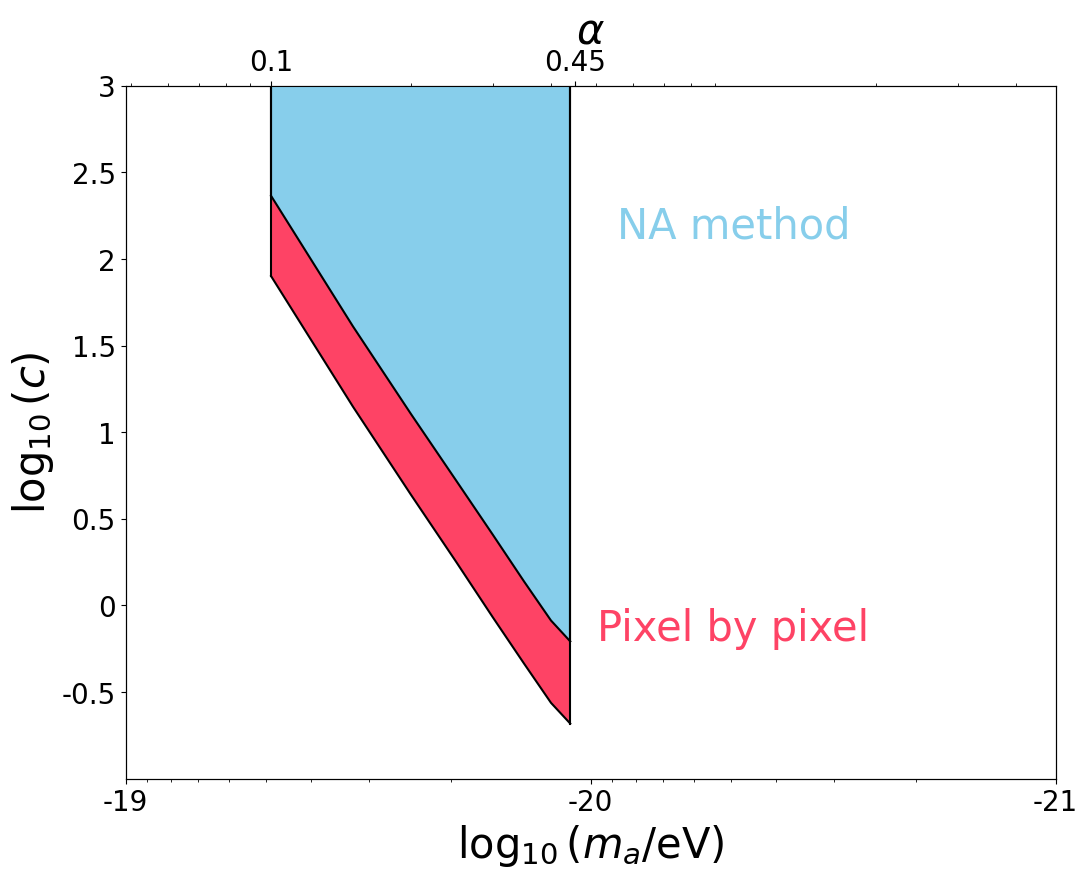

In [82]:
plt.clf()
fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xscale("log")
ax2 = ax.twiny()
ax2.set_xscale("log")
ax.set_ylim(-1, 3)
ax.set_yticks([-0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3])
ax.set_yticklabels(["-0.5", "0", "0.5", "1", "1.5", "2", "2.5", "3"], size=20)
ax.set_ylabel("$\log_{10}(c)$", size=30)
ax2.set_xticks([0.1, 0.45])
ax2.set_xticklabels(["0.1", "0.45"], size=20)
ax2.set_xlabel(r"$ \alpha $", size=30)
ax2.set_xlim(0.0486495, 4.86495)
ax.set_xlim(1e-19, 1e-21)
ax.set_xticks([1e-21, 1e-20, 1e-19])
ax.set_xticklabels(["-21", "-20", "-19"], size=20)
ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)
temp = np.load("new_static/l_cor_1d.npz")
# x1 = temp["omegas"]
# y1 = temp["cuts"]
x1 = final_cut1["alphas"]
y1 = final_cut1["cuts"]
yarray1 = deepcopy(y1)
temp = np.load("M_all/new_static/l_cor_dyn_obs.npz")
# x2 = temp["omegas"]
# y2 = temp["cuts"]
x2 = final_cut2["alphas"]
y2 = final_cut2["cuts"]
# y2[-2] = -1.09
# y2[-1] = -1.12
yarray2 = deepcopy(y2)


# for i in range(1,len(y2)-1):
#     yarray1[i] = (y1[i-1]+y1[i]+y1[i+1])/3.
#     yarray2[i] = (y2[i-1]+y2[i]+y2[i+1])/3.

ax2.plot(x1, yarray1, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray1[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray1[0], 6], "black")
ax2.plot(x2, yarray2, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray2[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray2[0], 6], "black")
xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
ax2.fill_between(x1, yarray1, 3, ls="-", lw=2, fc=xcolor[0], alpha=1)
ax2.fill_between(x1, yarray2, yarray1, ls="-", lw=2, fc=xcolor[2], alpha=1)
plt.annotate(
    "NA method",
    xy=(0.78, 0.78),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[0],
)
plt.annotate(
    "Pixel by pixel",
    xy=(0.8, 0.2),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[2],
)
plt.savefig(f"new_static/contract.pdf", dpi=600)

<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_177838/1386927692.py:9: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("$\log_{10}(c)$", size=30)
/tmp/ipykernel_177838/1386927692.py:17: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)


<Figure size 640x480 with 0 Axes>

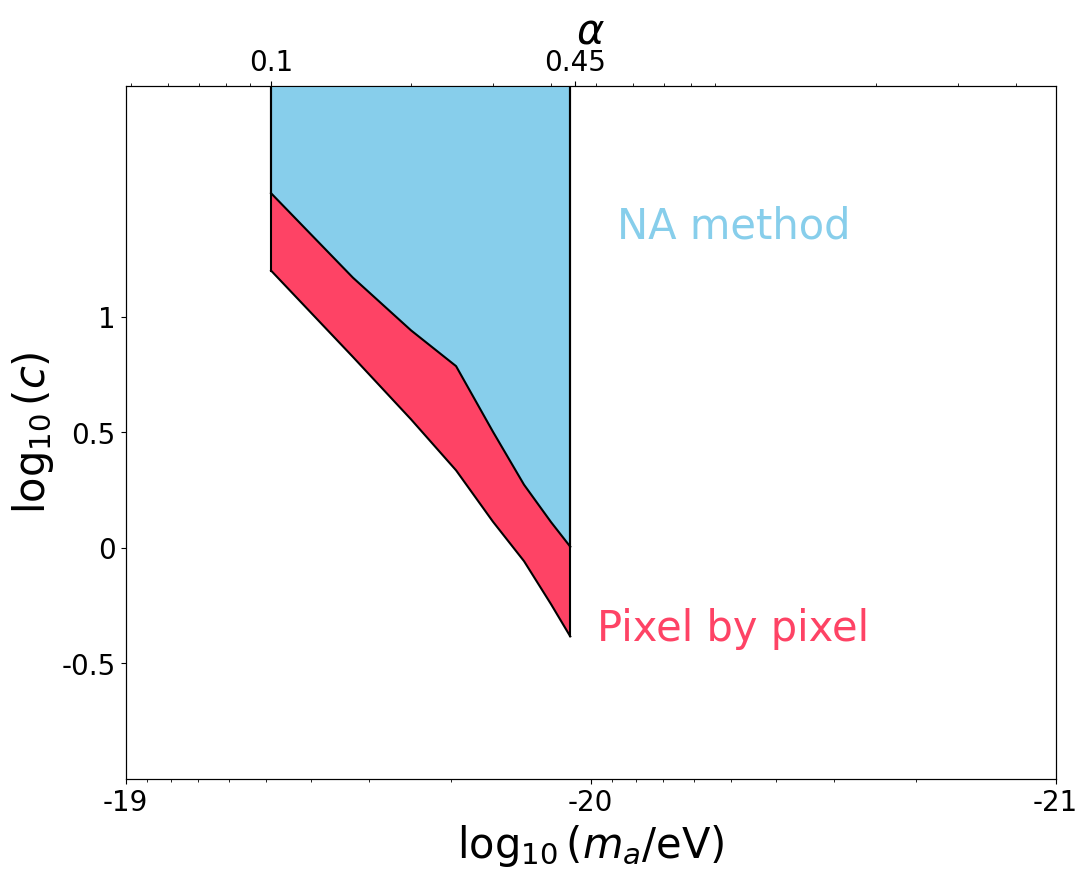

In [77]:
plt.clf()
fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xscale("log")
ax2 = ax.twiny()
ax2.set_xscale("log")
ax.set_ylim(-1, 2)
ax.set_yticks([-0.5, 0, 0.5, 1])
ax.set_yticklabels(["-0.5", "0", "0.5", "1"], size=20)
ax.set_ylabel("$\log_{10}(c)$", size=30)
ax2.set_xticks([0.1, 0.45])
ax2.set_xticklabels(["0.1", "0.45"], size=20)
ax2.set_xlabel(r"$ \alpha $", size=30)
ax2.set_xlim(0.0486495, 4.86495)
ax.set_xlim(1e-19, 1e-21)
ax.set_xticks([1e-21, 1e-20, 1e-19])
ax.set_xticklabels(["-21", "-20", "-19"], size=20)
ax.set_xlabel("$\log_{10}(m_a/\mathrm{eV})$", size=30)
temp = np.load("new_static/l_cor_1d.npz")
# x1 = temp["omegas"]
# y1 = temp["cuts"]
x1 = final_cut1["alphas"]
y1 = final_cut1["cuts"]
yarray1 = deepcopy(y1)
temp = np.load("M_all/new_static/l_cor_dyn_obs.npz")
# x2 = temp["omegas"]
# y2 = temp["cuts"]
x2 = final_cut2["alphas"]
y2 = final_cut2["cuts"]
# y2[-2] = -1.09
# y2[-1] = -1.12
yarray2 = deepcopy(y2)


# for i in range(1,len(y2)-1):
#     yarray1[i] = (y1[i-1]+y1[i]+y1[i+1])/3.
#     yarray2[i] = (y2[i-1]+y2[i]+y2[i+1])/3.

ax2.plot(x1, yarray1, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray1[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray1[0], 6], "black")
ax2.plot(x2, yarray2, "black")
ax2.plot([np.max(x1), np.max(x1)], [yarray2[-1], 6], "black")
ax2.plot([np.min(x1), np.min(x1)], [yarray2[0], 6], "black")
xcolor = ["SkyBlue", "#C8C8A9", "#FE4365"]
ax2.fill_between(x1, yarray1, 3, ls="-", lw=2, fc=xcolor[0], alpha=1)
ax2.fill_between(x1, yarray2, yarray1, ls="-", lw=2, fc=xcolor[2], alpha=1)
plt.annotate(
    "NA method",
    xy=(0.78, 0.78),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[0],
)
plt.annotate(
    "Pixel by pixel",
    xy=(0.8, 0.2),
    xycoords="axes fraction",
    ha="right",
    size=30,
    color=xcolor[2],
)
plt.savefig(f"new_static/contract.pdf", dpi=600)

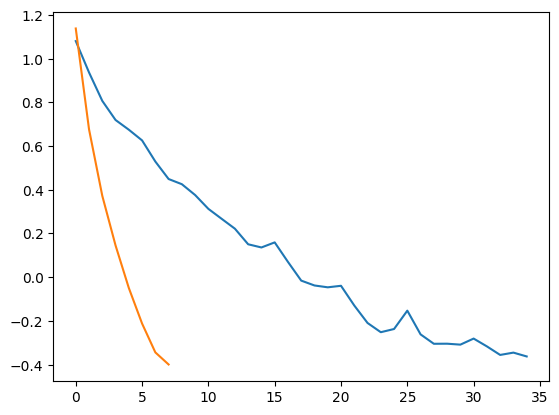

In [64]:
plt.plot(final_cut1["cuts"])
plt.plot(final_cut2["cuts"])

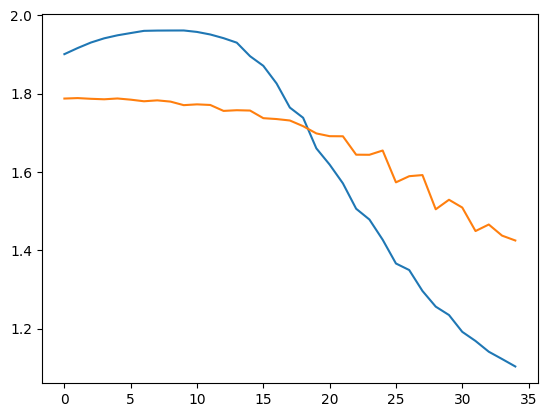

In [160]:
plt.plot(final_cut1["cuts"])
plt.plot(final_cut2["cuts"])

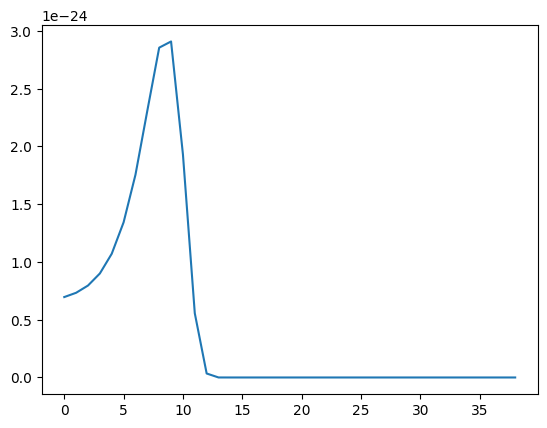

In [32]:
plt.plot(np.diff(prgagg))

In [ ]:
final_cut[34] - final_cut[0]

np.float64(-1.3126400088088257)

In [ ]:
All_data = np.load(f"./EHT-Imaging/101_all_data.npy")
theta_data101 = 0.5 * np.arctan2(
    np.mean(All_data[:, :, :, 2], axis=0), np.mean(All_data[:, :, :, 1], axis=0)
)  # rad

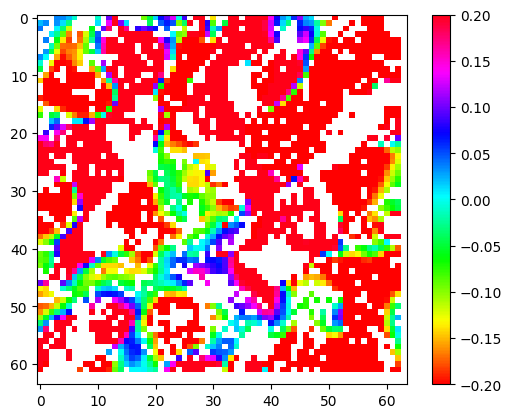

In [ ]:
plt.imshow(CircleCalc.circle_sub_evpa(theta_mean[1], theta_mean[0]), cmap="hsv")
plt.colorbar()
plt.clim(-0.2, 0.2)

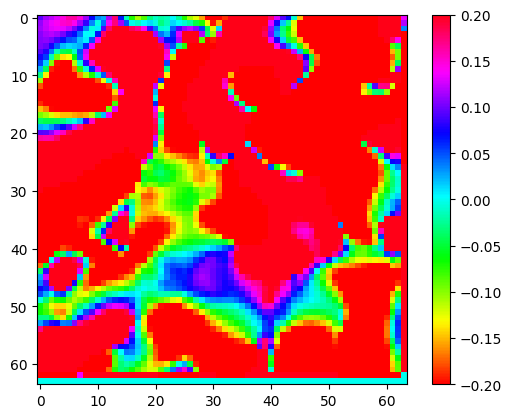

In [ ]:
plt.imshow(CircleCalc.circle_sub_evpa(theta_data96, theta_data95), cmap="hsv")
plt.colorbar()
plt.clim(-0.2, 0.2)

In [ ]:
jj = theta_mean[1] - theta_mean[0]
jj[np.sqrt(theta_std[1] * theta_std[1] + theta_std[0] * theta_std[0]) > 0.3] = np.nan

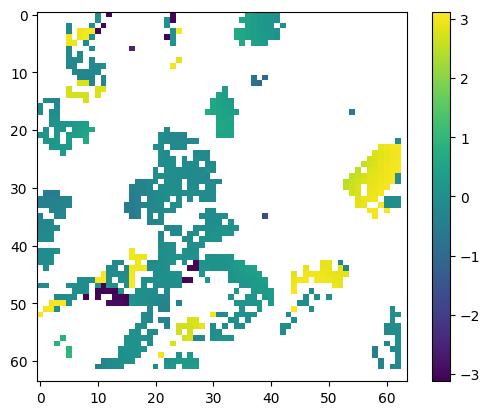

In [137]:
plt.imshow(jj)
plt.colorbar()
# plt.clim(-0.2,0.2)

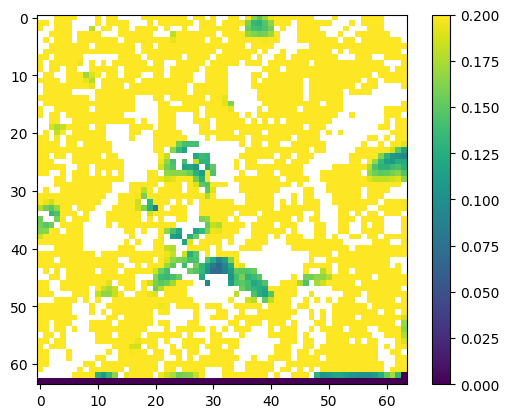

In [ ]:
plt.imshow(np.sqrt(theta_std[1] * theta_std[1] + theta_std[0] * theta_std[0]))
plt.colorbar()
plt.clim(0, 0.2)

In [ ]:
cor_std_good[0, 1, 1]

np.float64(0.4512943525439286)

In [ ]:
(np.asarray([np.diag(Delta_std[0]), np.diag(Delta_std[1])])[:, goodsetrow, goodsetcol])[
    0
].min()

np.float64(0.0)

In [ ]:
jj = np.asarray([np.diag(Delta_std[0]), np.diag(Delta_std[1])])[
    :, goodsetrow, goodsetcol
]

In [ ]:
np.array([jj[1, i, i] for i in range(237)]).min()

np.float64(0.11598372425616639)

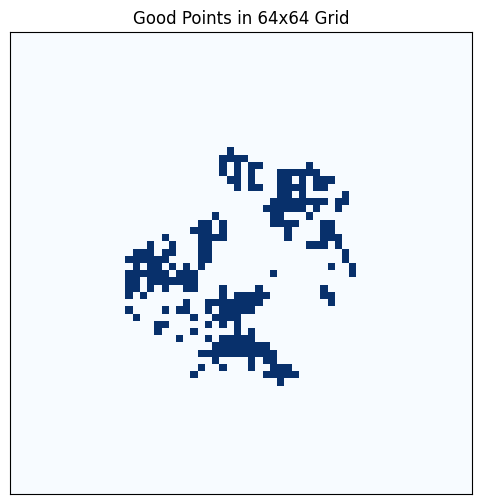

In [ ]:
grid = np.zeros((64, 64))

# 把 goodset 里的点设为 1
for num in goodset:
    x, y = divmod(num, 64)
    grid[x, y] = 1

# 画图
plt.figure(figsize=(6, 6))
plt.imshow(grid, cmap="Blues", origin="upper")  # 颜色用蓝色
plt.xticks([])
plt.yticks([])
plt.title("Good Points in 64x64 Grid")
plt.show()

In [ ]:
[cor_std + cor_grmhd + tmpCorAxion[i] * (gagg[g] * gagg[g]) for i in range(16)]

[array([[[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan,  0.,  0.],
         [nan, nan, nan, ...,  0., nan,  0.],
         [nan, nan, nan, ...,  0.,  0., nan]],
 
        [[nan,  0.,  0., ..., nan, nan,  0.],
         [ 0., nan,  0., ..., nan, nan,  0.],
         [ 0.,  0., nan, ..., nan, nan,  0.],
         ...,
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [ 0.,  0.,  0., ..., nan, nan, nan]]]),
 array([[[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan,  0.,  0.],
         [nan, nan, nan, ...,  0., nan,  0.],
         [nan, nan, nan, ...,  0.,  0., nan]],
 
        [[nan,  0.,  0., ..., nan, nan,  0.],
         [ 0., nan,  0., ..., nan, nan,  0.],
         [ 0.,  0., nan, ...,

In [83]:
final_cut

[np.float64(1.501703368559929),
 np.float64(1.4906423571358534),
 np.float64(1.4007462096465821),
 np.float64(1.2690943382366104),
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [ ]:
theta_data_1d_786[theta_data_1d_786 > np.pi / 2] -= np.pi
theta_data_1d_786[theta_data_1d_786 < -np.pi / 2] += np.pi

In [ ]:
np.save("Plot/theta_data_1d_786_4", theta_data_1d_786)